# Лекция 5. CLIP: zero-shot-классификация и мультимодальный поиск

Курс «Современное компьютерное зрение»

Блокнот состоит из двух частей.

- **Часть I. Теория** — подробный учебный текст: от идеи обучения по естественному языку до устройства CLIP, zero-shot-классификации, мультимодального поиска, ограничений, способов адаптации и потомков CLIP (OpenCLIP, SigLIP и др.). В тексте разобраны числовые примеры.
- **Часть II. Практика** — исполняемые примеры на реальных данных (Flickr8k, CIFAR-10). Функция потерь на реальном батче, zero-shot с разными промптами и статистической проверкой, калибровка, сравнение с few-shot, поиск по тексту и по изображению, модальный разрыв, типографская атака, порядок слов, подсчёт, мини-обучение проекций, сравнение с SigLIP.

Как запускать:

1. Откройте блокнот в Google Colab.
2. Выберите «Среда выполнения → Сменить среду выполнения → T4 GPU». Блокнот работает и на CPU, но медленнее.
3. Выполните «Среда выполнения → Выполнить все». Никаких ключей API не нужно: модели и данные загружаются с Hugging Face Hub.

Числа в выводах ячеек получены при запуске; на другой версии библиотек или на GPU они могут незначительно отличаться. Интерпретации в тексте сформулированы так, чтобы оставаться верными при таких колебаниях; если у вас получилось иначе — это повод для обсуждения на семинаре.

## Содержание

Часть I. Теория
1. Зачем учить зрение по тексту
2. Устройство CLIP: данные, архитектура, функция потерь, обучение
3. Zero-shot-классификация
4. Мультимодальный поиск
5. Геометрия общего пространства
6. Ограничения и риски
7. Адаптация CLIP к своей задаче
8. После CLIP: ALIGN, OpenCLIP, DataComp, MetaCLIP, SigLIP
9. Рецепт для курсового проекта

Часть II. Практика (разделы 0–12)

Контрольные вопросы, задания и источники — в конце блокнота.

# Часть I. Теория

## 1. Зачем учить зрение по тексту

### 1.1. Ограничение закрытого словаря

Классический классификатор изображений обучается предсказывать один из $C$ заранее фиксированных классов: 1000 классов ImageNet, 80 категорий COCO. Это порождает три проблемы.

1. **Новый класс — новая разметка.** Чтобы добавить категорию «электросамокат», нужно собрать и разметить примеры и дообучить модель.
2. **Метка беднее изображения.** Метка «собака» ничего не говорит о том, что собака мокрая, бежит по пляжу и держит в зубах палку, хотя всё это видно на снимке.
3. **Классы — это решение составителя датасета.** Границы между «automobile» и «truck» в CIFAR-10 произвольны, и модель выучивает именно их.

Естественный язык снимает все три ограничения. Подписи к изображениям в интернете существуют в огромном количестве, описывают сцену гораздо богаче одной метки, а новый класс задаётся просто новой фразой. Авторы CLIP формулируют это так: обучение по языку не требует разметки в «машинно-удобном» формате 1-из-N и связывает представление с языком, что даёт гибкий zero-shot-перенос ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)).

### 1.2. Предшественники

Идея не нова, и обзор в статье CLIP прослеживает её больше чем на 20 лет назад ([Radford et al., разд. 1](https://arxiv.org/abs/2103.00020)):

| Работа | Что сделано |
|---|---|
| Mori et al., 1999 | предсказание существительных и прилагательных из документа по изображению для поиска |
| Joulin et al., 2016 | CNN предсказывает слова из заголовков и описаний YFCC100M (мешок слов) |
| Visual N-Grams (Li et al., 2017) | словарь из 142 806 визуальных n-грамм; первый zero-shot-перенос на стандартные датасеты: 11.5% на ImageNet |
| VirTex, ICMLM, ConVIRT (2020) | трансформеры и контрастные цели для обучения зрения по тексту; ConVIRT — контраст «снимок–отчёт» в медицине |

Препятствием был масштаб. Эти работы обучались на сотнях тысяч изображений, тогда как обучение с учителем на зашумлённых метках (Instagram-хэштеги, JFT-300M) шло на сотнях миллионов и миллиардах. CLIP закрывает этот разрыв: 400 млн пар и «упрощённый ConVIRT» ([Radford et al.](https://arxiv.org/abs/2103.00020)).

### 1.3. Почему контраст, а не генерация подписи

Первая попытка авторов была похожа на VirTex: обучить CNN и трансформер с нуля генерировать подпись к изображению. Это масштабировалось плохо.

- Трансформер-языковая модель на 63 млн параметров уже тратила вдвое больше вычислений, чем её ResNet-50. При этом zero-shot-распознавание классов ImageNet она выучивала в 3 раза медленнее, чем простая модель, предсказывающая мешок слов подписи.
- Замена предсказательной цели на контрастную (угадать, какая подпись целиком парна изображению, а не её точные слова) дала ещё 4-кратный выигрыш в эффективности ([Radford et al., рис. 2](https://arxiv.org/abs/2103.00020)).

Интуиция такая. Предсказать точные слова подписи очень трудно: к одной фотографии можно написать тысячи разных подписей, и модель тратит ёмкость на стиль, порядок слов и детали, не нужные для распознавания. Задача «какая из $N$ подписей подходит» проще и сосредоточена на соответствии содержания. Это прямое продолжение идеи контрастного обучения из лекции 4 (InfoNCE, SimCLR, MoCo), только позитивная пара теперь — изображение и его текст, а не два вида одного изображения.

## 2. Устройство CLIP

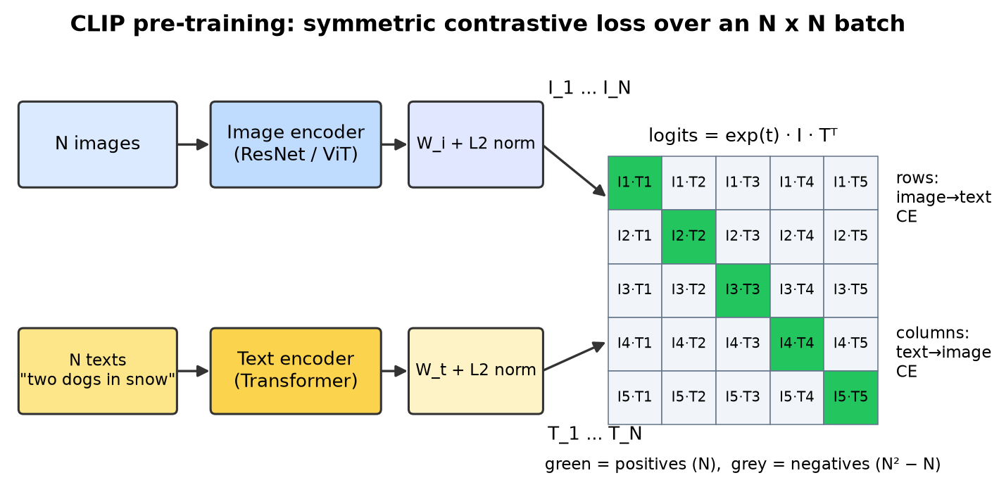

Рис. 1. Схема обучения CLIP: два энкодера, линейные проекции в общее пространство, матрица сходств $N\times N$ и симметричная кросс-энтропия по строкам и столбцам.

### 2.1. Данные: WIT

Существующие наборы были либо качественными, но маленькими (MS-COCO и Visual Genome — около 100 тыс. фотографий), либо большими, но с бедными метаданными (YFCC100M после фильтрации англоязычных описаний сократился до 15 млн). Поэтому авторы собрали собственный набор WIT (WebImageText) — 400 млн пар (изображение, текст) из публично доступных источников ([Radford et al., разд. 2.2](https://arxiv.org/abs/2103.00020)).

- Чтобы покрыть как можно больше визуальных понятий, искались пары, текст которых содержит один из 500 000 запросов.
- Базовый список — все слова, встречающиеся в английской Википедии не менее 100 раз. Он дополнен биграммами с высокой взаимной информацией, названиями популярных статей Википедии и синсетами WordNet.
- Для приблизительной балансировки бралось до 20 000 пар на запрос.
- По общему числу слов WIT сопоставим с WebText, на котором обучалась GPT-2.

Сам WIT не опубликован. Позднее это сделало открытые воспроизведения (LAION, DataComp, MetaCLIP; раздел 8) отдельным направлением исследований: как собрать данные, на которых CLIP учится так же хорошо.

### 2.2. Архитектура: два энкодера

CLIP — dual encoder: изображение и текст кодируются независимо, и взаимодействуют они только через скалярное произведение эмбеддингов.

**Энкодер изображений** — один из двух вариантов ([Radford et al., разд. 2.4](https://arxiv.org/abs/2103.00020)).

- ResNet-50 с улучшениями ResNet-D и антиалиасинговым blur pooling. Глобальный average pooling заменён attention pooling: один слой multi-head QKV-внимания, где запросом служит усреднённое представление изображения. Масштабирование следует идее EfficientNet: ширина, глубина и разрешение увеличиваются одновременно. Обучено 5 моделей: RN50, RN101, RN50x4, RN50x16, RN50x64, где RN50x64 требует примерно в 64 раза больше вычислений, чем RN50.
- Vision Transformer с небольшой модификацией: дополнительная нормализация слоя после сложения эмбеддингов патчей и позиций. Обучено 3 модели: ViT-B/32, ViT-B/16, ViT-L/14. Признак изображения — выход токена [CLS].

**Энкодер текста** — трансформер в стиле GPT-2.

- Базовый размер — 63 млн параметров: 12 слоёв, ширина 512, 8 голов внимания.
- Текст переводится в нижний регистр и кодируется BPE со словарём 49 152 токена.
- Длина ограничена 76 токенами. В реализации Hugging Face это 77 позиций вместе со служебными токенами.
- Последовательность обрамляется токенами [SOS] и [EOS]. Признак текста — активации последнего слоя на позиции [EOS] после нормализации слоя.
- Внимание маскированное (каузальное). Авторы оставили его, чтобы сохранить возможность инициализации языковой моделью, но этим не воспользовались.
- При масштабировании моделей увеличивалась только ширина текстового энкодера: качество CLIP оказалось мало чувствительно к его ёмкости.

**Проекции.** Признаки обоих энкодеров линейно проецируются в общее пространство размерности $d$ (512 для ViT-B/32) и нормируются:

$$
I_e=\frac{W_i\,f_{\text{img}}(x)}{\|W_i\,f_{\text{img}}(x)\|},\qquad T_e=\frac{W_t\,f_{\text{txt}}(t)}{\|W_t\,f_{\text{txt}}(t)\|}.
$$

В отличие от SimCLR, нелинейная проекционная голова не используется: авторы не заметили разницы в эффективности и предположили, что нелинейные головы связаны со спецификой самообучения на одних изображениях ([Radford et al., разд. 2.3](https://arxiv.org/abs/2103.00020)).

Модели обучались с нуля: ни энкодер изображений не инициализировался весами ImageNet, ни текстовый энкодер — предобученной языковой моделью.

### 2.3. Функция потерь

Пусть в батче $N$ пар $(x_k,t_k)$, их нормированные эмбеддинги — $I_k$ и $T_k$, а $s=e^{\theta}$ — обучаемый масштаб, обратный температуре ($s=1/\tau$). Матрица логитов:

$$
z_{ij}=s\,I_i^\top T_j,\qquad i,j=1,\dots,N.
$$

Потеря — среднее двух кросс-энтропий: по строкам (для каждого изображения выбрать его текст среди $N$) и по столбцам (для каждого текста выбрать его изображение):

$$
\mathcal L_{I\to T}=-\frac1N\sum_{i=1}^N\log\frac{e^{z_{ii}}}{\sum_{j=1}^N e^{z_{ij}}},\qquad
\mathcal L_{T\to I}=-\frac1N\sum_{j=1}^N\log\frac{e^{z_{jj}}}{\sum_{i=1}^N e^{z_{ij}}},\qquad
\mathcal L=\tfrac12\big(\mathcal L_{I\to T}+\mathcal L_{T\to I}\big).
$$

Каждая строка — это InfoNCE из лекции 4 с одним позитивом и $N-1$ негативами. При батче 32 768 у каждого изображения 32 767 негативных текстов. Всего в батче $N$ позитивных и $N^2-N$ негативных пар. Авторы отмечают, что эта конструкция восходит к multi-class N-pair loss (Sohn, 2016) и InfoNCE (Oord et al., 2018), а для пар «изображение–текст» впервые применена в ConVIRT ([Radford et al., разд. 2.3](https://arxiv.org/abs/2103.00020)).

Псевдокод из статьи ([Radford et al., рис. 3](https://arxiv.org/abs/2103.00020)):

```python
I_f = image_encoder(I)                      # [n, d_i]
T_f = text_encoder(T)                       # [n, d_t]
I_e = l2_normalize(np.dot(I_f, W_i), axis=1)
T_e = l2_normalize(np.dot(T_f, W_t), axis=1)
logits = np.dot(I_e, T_e.T) * np.exp(t)     # [n, n]
labels = np.arange(n)
loss_i = cross_entropy_loss(logits, labels, axis=0)
loss_t = cross_entropy_loss(logits, labels, axis=1)
loss = (loss_i + loss_t) / 2
```

**Градиент.** Обозначим через $P_{ij}$ softmax по строке $i$, через $Q_{ij}$ — softmax по столбцу $j$. Дифференцируя, получаем

$$
\frac{\partial\mathcal L}{\partial z_{ij}}=\frac1{2N}\Big(P_{ij}+Q_{ij}-2\,\mathbb 1[i=j]\Big).
$$

Отсюда видно, как работает обучение:

- для позитивной пары градиент отрицателен ($P_{ii}+Q_{ii}-2<0$): сходство увеличивается;
- для негативной пары градиент положителен и пропорционален тому, насколько модель уже считает её правдоподобной ($P_{ij}+Q_{ij}$). Сильнее всего отталкиваются трудные негативы — похожие, но чужие подписи.

**Численный пример.** $N=3$, $s=100$, косинусы первого изображения с тремя текстами: 0.31 (свой), 0.28, 0.22. Логиты 31, 28, 22, вычитаем максимум: 0, −3, −9. Тогда

$$
P_{1\cdot}=\frac{(1,\ e^{-3},\ e^{-9})}{1+e^{-3}+e^{-9}}\approx(0.952,\ 0.047,\ 0.0001),\qquad -\log P_{11}\approx0.049.
$$

Разница косинусов всего 0.03 превращается в уверенность 95%. Именно поэтому малые абсолютные косинусы CLIP (около 0.3 для верных пар) не мешают уверенным предсказаниям. Важен порядок, а остроту задаёт масштаб.

Если бы $s=1$, те же косинусы дали бы почти равномерное распределение $(0.35,0.34,0.32)$, и потеря была бы близка к $\ln 3$. В практике (раздел 3) это проверяется на реальном батче.

**Связь со взаимной информацией.** Как показано в лекции 4, InfoNCE с $N$ кандидатами даёт нижнюю оценку взаимной информации $I(\text{image};\text{text})\ge\log N-\mathcal L$ ([Oord et al.](https://arxiv.org/abs/1807.03748)). Огромный батч CLIP — это не только «больше негативов», но и более высокий потолок этой оценки.

### 2.4. Обучаемая температура

В SimCLR и MoCo температура — гиперпараметр. В CLIP параметр $\theta=\log s$ обучается вместе с сетью ([Radford et al., разд. 2.5](https://arxiv.org/abs/2103.00020)):

- инициализация соответствует $\tau=0.07$, то есть $s\approx14.3$, как у Wu et al. (2018);
- масштаб ограничен сверху значением 100: без этого обучение было неустойчивым.

Почему масштаб растёт. Продифференцируем потерю по $\theta$:

$$
\frac{\partial\mathcal L}{\partial\theta}=\sum_{i,j}z_{ij}\frac{\partial\mathcal L}{\partial z_{ij}}
=\frac{s}{2N}\Big[\sum_i\big(\mathbb E_{P_{i\cdot}}[c_{i\cdot}]-c_{ii}\big)+\sum_j\big(\mathbb E_{Q_{\cdot j}}[c_{\cdot j}]-c_{jj}\big)\Big],
$$

где $c_{ij}=I_i^\top T_j$ — косинусы. Если косинус позитива больше среднего по softmax-распределению (модель в основном права), производная отрицательна, и градиентный спуск увеличивает $s$. Так модель «заостряет» распределение по мере обучения. У обученной ViT-B/32 масштаб равен ровно 100: ограничение достигнуто. Это видно в первой ячейке практики, а в разделе 10 практики виден медленный рост масштаба при обучении случайных проекций.

### 2.5. Режим обучения

Детали из [Radford et al., разд. 2.5](https://arxiv.org/abs/2103.00020):

| Параметр | Значение |
|---|---|
| Модели | 5 ResNet (RN50, RN101, RN50x4, RN50x16, RN50x64) и 3 ViT (B/32, B/16, L/14) |
| Эпохи | 32 по 400 млн пар |
| Батч | 32 768 |
| Оптимизатор | Adam с decoupled weight decay (кроме gain и bias), косинусное расписание |
| Аугментации | только случайный квадратный кроп из масштабированного изображения |
| Память и скорость | mixed precision, gradient checkpointing, статистики Adam в половинной точности, шардирование матрицы сходств по GPU |
| Вычисления | RN50x64 — 18 дней на 592 V100; ViT-L/14 — 12 дней на 256 V100 |
| Лучшая модель | ViT-L/14, дообученная одну эпоху на разрешении 336 (ViT-L/14@336px) |

Обратите внимание на минимальные аугментации. В лекции 4 мы видели, что для SimCLR цветовые искажения критичны. Здесь они не нужны: второй вид — текст, и тривиального решения через цветовую гистограмму нет.

Гиперпараметры подбирались на базовой ResNet-50 при обучении на одной эпохе. Для больших моделей их адаптировали эвристически из-за ограничений вычислений.

## 3. Zero-shot-классификация

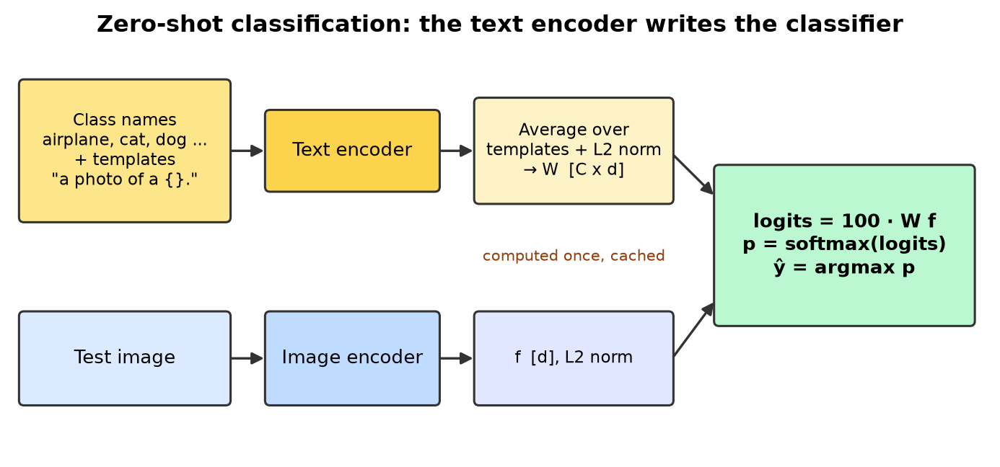

Рис. 2. Zero-shot-классификатор: текстовый энкодер превращает названия классов в веса линейного классификатора, которые вычисляются один раз и кэшируются.

### 3.1. Как это устроено

Для задачи с классами $c=1,\dots,C$ текстовый энкодер кодирует фразы вида «a photo of a {класс}.» и даёт нормированные векторы $w_c$. Для изображения с эмбеддингом $f$:

$$
p(c\mid x)=\frac{\exp\big(s\,w_c^\top f\big)}{\sum_{k=1}^C\exp\big(s\,w_k^\top f\big)},\qquad\hat y=\arg\max_c\,w_c^\top f.
$$

Авторы дают две полезные интерпретации ([Radford et al., разд. 3.1.2](https://arxiv.org/abs/2103.00020)):

1. Это мультиномиальная логистическая регрессия с L2-нормированными входами и весами, без смещения и с температурой. Энкодер изображений — обычный backbone, а энкодер текста — гиперсеть, генерирующая веса линейного классификатора по описанию классов.
2. Каждый шаг обучения CLIP можно рассматривать как обучение на случайно сгенерированном «датасете» с 32 768 классами, заданными текстом, по одному примеру на класс. Zero-shot-классификация — та же задача, только классы задаёт пользователь.

Веса $w_c$ вычисляются один раз, поэтому стоимость классификации не зависит от того, сколько промптов использовалось.

**Что значит zero-shot.** Классическое zero-shot learning — обобщение на невиданные категории. CLIP использует термин шире: перенос на невиданные датасеты без обучения на них. Модель могла видеть кошек в WIT, но не видела ни одного обучающего примера CIFAR-10 с меткой. Авторы подчёркивают: на датасетах вроде CIFAR-10 zero-shot проверяет скорее устойчивость к сдвигу распределения, чем способность к новой задаче ([Radford et al., разд. 3.1.1](https://arxiv.org/abs/2103.00020)).

### 3.2. Промпт-инжиниринг

Имя класса само по себе — плохой промпт. Причины ([Radford et al., разд. 3.1.4](https://arxiv.org/abs/2103.00020)):

- **Многозначность.** В ImageNet есть и подъёмный кран, и журавль — оба «crane». В Oxford-IIIT Pets «boxer» — порода собаки, но без контекста это может быть и боксёр-спортсмен.
- **Сдвиг распределения текста.** В обучающих данных подпись из одного слова редкость; обычно это предложение. Шаблон «A photo of a {label}.» сообщает, что текст описывает содержание изображения. Только он повышает точность на ImageNet на 1.3%.
- **Контекст задачи помогает:**
  - для Pets — «A photo of a {label}, a type of pet.»;
  - для Food101 — упоминание еды, для FGVC Aircraft — самолёта;
  - для OCR-датасетов — кавычки вокруг распознаваемого текста или числа;
  - для спутниковых снимков — «a satellite photo of a {label}.».

### 3.3. Ансамбль промптов

Ансамбль строится по нескольким шаблонам: «a photo of a big {}», «a blurry photo of a {}» и т. д. Важная деталь: усреднение делается в пространстве эмбеддингов, а не вероятностей:

$$
w_c=\frac{\sum_{m=1}^{M}T_e\big(\text{template}_m(c)\big)}{\Big\|\sum_{m=1}^{M}T_e\big(\text{template}_m(c)\big)\Big\|}.
$$

Так ансамбль из $M$ промптов стоит при инференсе столько же, сколько один: усреднённые веса кэшируются.

Результаты ([Radford et al., разд. 3.1.4, рис. 4](https://arxiv.org/abs/2103.00020)):

- на ImageNet ансамбль из 80 шаблонов даёт ещё +3.5% поверх одного шаблона по умолчанию;
- вместе промпт-инжиниринг и ансамбль улучшают ImageNet почти на 5%;
- в среднем по 36 датасетам выигрыш почти 5 пунктов, что сопоставимо с переходом к модели, требующей в 4 раза больше вычислений.

Развитие идеи — генерация описаний классов языковой моделью: CuPL ([Pratt et al.](https://arxiv.org/abs/2209.03320)) просит LLM описать, как выглядит класс, и использует эти описания как промпты. Это даёт более точные промпты при гораздо меньшем числе написанных вручную шаблонов.

### 3.4. Насколько хорошо работает zero-shot

**Сравнение с Visual N-Grams** ([Radford et al., табл. 1](https://arxiv.org/abs/2103.00020)):

| Датасет | Visual N-Grams | CLIP |
|---|---|---|
| aYahoo | 72.4 | 98.4 |
| ImageNet | 11.5 | 76.2 |
| SUN | 23.0 | 58.5 |

76.2% на ImageNet — это уровень исходного ResNet-50, обученного с учителем на 1.28 млн размеченных изображений, без использования ни одного из них. Top-5 точность 95% соответствует Inception-V4. Авторы оговаривают, что это сравнение контекстуализирует результат, а не сравнивает методы. Данных в 10 раз больше, вычислений на предсказание почти в 100 раз больше, а архитектуры трансформера при создании Visual N-Grams не существовало.

**Сравнение с обученным линейным классификатором.** Zero-shot CLIP сравнили с логистической регрессией, обученной с учителем на признаках ResNet-50. Zero-shot выигрывает на 16 из 27 датасетов, включая ImageNet ([Radford et al., рис. 5](https://arxiv.org/abs/2103.00020)). Разброс показателен (разница в п.п.):

| Сильнее всего выигрывает | Δ | Сильнее всего проигрывает | Δ |
|---|---|---|---|
| StanfordCars | +28.9 | EuroSAT (спутник) | −37.1 |
| Country211 (геолокация) | +23.2 | KITTI Distance | −34.0 |
| Food101 | +22.5 | PatchCamelyon (гистология) | −19.5 |
| Kinetics700 (действия) | +14.5 | GTSRB (дорожные знаки) | −18.4 |
| SST2 (текст на картинке) | +12.4 | CLEVRCounts (подсчёт) | −18.2 |

Закономерность: CLIP силён там, где понятия часто встречаются в интернет-подписях (марки машин, блюда, страны, действия). Он слаб на специализированных, абстрактных или систематических задачах: спутниковые снимки, медицина, подсчёт, расстояния. На MNIST zero-shot CLIP даёт только 88%, и его обгоняет логистическая регрессия на сырых пикселях. В WIT почти нет изображений, похожих на рукописные цифры MNIST ([Radford et al., разд. 6 и прил. E.2](https://arxiv.org/abs/2103.00020)). Для домена курсового проекта (медицина, промышленность, спутник) zero-shot — это baseline, а не решение.

**Zero-shot против few-shot.** Можно было бы ожидать, что даже один размеченный пример лучше описания. Оказалось иначе: zero-shot CLIP соответствует 4-shot логистической регрессии на тех же признаках и почти достигает лучшего 16-shot результата среди публичных моделей ([Radford et al., рис. 6](https://arxiv.org/abs/2103.00020)). Объяснение авторов: текст прямо сообщает понятие, а по одному примеру неясно, какой из многих видимых визуальных признаков важен. Простое сочетание zero-shot и few-shot через L2-штраф к текстовым весам не сработало. Подбор гиперпараметров выбирал такой сильный штраф, что классификатор становился просто zero-shot. Более удачные способы сочетания — в разделе 7.

**CIFAR-10 для модели из практики.** У ViT-B/32: zero-shot — 91.3%, linear probe на тех же признаках — 95.1% ([Radford et al., табл. 10–11](https://arxiv.org/abs/2103.00020)). Эти числа — ориентир для раздела 4 практики.

### 3.5. Робастность к сдвигу распределения

Модели, обученные на ImageNet, теряют много точности на ImageNetV2, ImageNet-Sketch, ObjectNet, ImageNet-R и ImageNet-A. Авторы используют понятие effective robustness: превышение точности на сдвинутом распределении над тем, что предсказывает линейный тренд для моделей ImageNet с той же исходной точностью.

Выводы ([Radford et al., разд. 3.3](https://arxiv.org/abs/2103.00020)):

- zero-shot CLIP сокращает разрыв робастности до 75%;
- если адаптировать CLIP к ImageNet логистической регрессией, точность на ImageNet растёт, но выигрыш в робастности почти исчезает. Модель начинает опираться на корреляции, специфичные для ImageNet.

Отсюда метод WiSE-FT ([Wortsman et al.](https://arxiv.org/abs/2109.01903)) — усреднение весов zero-shot и дообученной модели (раздел 7).

### 3.6. Пересечение с данными предобучения

Обученная на 400 млн веб-изображений модель могла видеть тестовые изображения бенчмарков. Авторы построили детектор почти-дубликатов и сравнили точность на «пересекающейся» и «чистой» частях. Статистически значимых улучшений из-за пересечения почти нет. Например, у Country211 доля пересечения 21.5%, но прирост точности всего 0.2% ([Radford et al., разд. 5](https://arxiv.org/abs/2103.00020)). Для вашего домена такую проверку никто не делал. Если тестовые изображения взяты из интернета, учитывайте этот риск.

## 4. Мультимодальный поиск

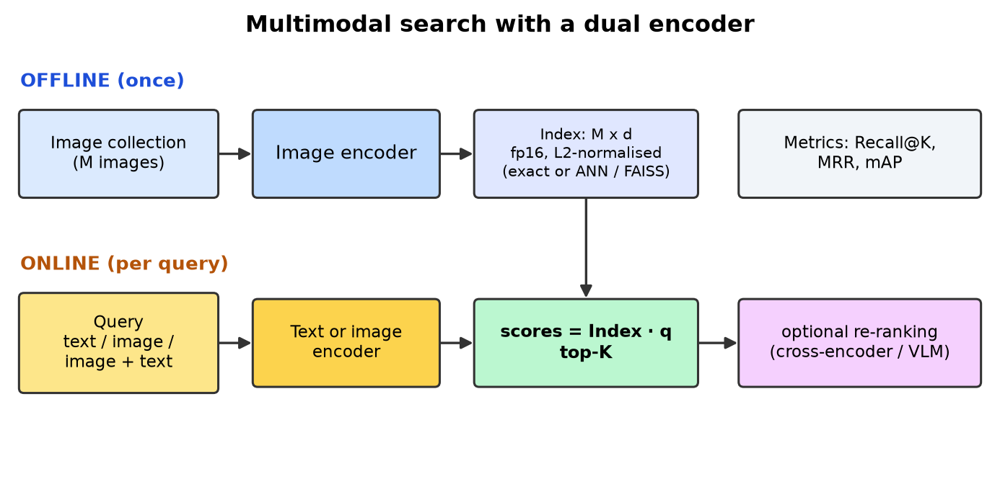

Рис. 3. Поиск с dual encoder: изображения кодируются один раз в индекс, каждый запрос кодируется отдельно, а ранжирование — это скалярное произведение. Переранжирование более тяжёлой моделью — необязательная вторая стадия.

### 4.1. Постановка

Общее пространство позволяет решать несколько задач одной моделью:

| Задача | Запрос | Индекс | Пример |
|---|---|---|---|
| Text → image | текст | изображения | «красный трактор в поле» в фотоархиве |
| Image → text | изображение | тексты | подбор подписи или категории из каталога |
| Image → image | изображение | изображения | поиск похожих товаров, дубликатов |
| Составной запрос | изображение + текст | изображения | «как это, но на пляже» |

Для нормированных эмбеддингов косинусное сходство равно скалярному произведению, и ранжирование всего индекса — одно матричное умножение:

$$
\text{scores}=E_{\text{index}}\,q,\qquad E_{\text{index}}\in\mathbb R^{M\times d},\ q\in\mathbb R^{d},\ \|q\|=1.
$$

**Dual encoder против cross-encoder.**

- Dual encoder (CLIP) кодирует изображения независимо от запроса. Индекс считается один раз, и запрос стоит одного прохода текстового энкодера плюс $M$ скалярных произведений.
- Cross-encoder (UNITER, VLM с перекрёстным вниманием) смотрит на пару целиком и понимает связи между словами и областями изображения лучше. Но он требует прохода сети на каждую пару «запрос–кандидат», то есть $M$ проходов на запрос.

Отсюда стандартная двухстадийная схема: CLIP отбирает top-K (например, 100) кандидатов, тяжёлая модель переранжирует их.

### 4.2. Метрики

Пусть для запроса $q$ множество релевантных объектов — $G_q$, а $\mathrm{rank}_q$ — позиция первого релевантного в выдаче (с 1).

$$
\mathrm{Recall@K}=\frac1{|Q|}\sum_{q\in Q}\mathbb 1\big[\mathrm{rank}_q\le K\big],\qquad
\mathrm{MRR}=\frac1{|Q|}\sum_{q\in Q}\frac1{\mathrm{rank}_q}.
$$

Соглашения в бенчмарках Flickr30k и COCO:

- в text → image у каждой подписи одно релевантное изображение;
- в image → text у каждого изображения 5 подписей, и засчитывается попадание любой из них в top-K;
- поэтому I→T R@1 обычно выше T→I R@1.

Если релевантных объектов много (поиск по каталогу), используют mean Average Precision или nDCG. Recall@K с одним эталоном занижает качество: модель может найти другие подходящие изображения, которые эталоном не являются. Это видно в анализе ошибок в практике.

### 4.3. Результаты CLIP

Zero-shot CLIP превосходит все предыдущие zero-shot-результаты на Flickr30k и MSCOCO. На Flickr30k text retrieval он сопоставим с лучшими дообученными моделями того времени ([Radford et al., табл. 13](https://arxiv.org/abs/2103.00020)):

| Модель | Режим | Flickr30k I→T R@1 | Flickr30k T→I R@1 | COCO 5k I→T R@1 | COCO 5k T→I R@1 |
|---|---|---|---|---|---|
| UNITER | fine-tuned | 87.3 | 75.6 | 65.7 | 52.9 |
| ERNIE-ViL | fine-tuned | 88.7 | 76.7 | — | — |
| Oscar | fine-tuned | — | — | 73.5 | 57.5 |
| UNITER | zero-shot | 83.6 | 68.7 | — | — |
| CLIP (ViT-L/14@336px) | zero-shot | 88.0 | 68.7 | 58.4 | 37.8 |

Две детали:

- на COCO, где кандидатов в 5 раз больше и подписи разнообразнее, дообученные модели заметно сильнее zero-shot CLIP;
- префикс «a photo of» перед подписью повышал R@1 на 1–2 пункта.

ALIGN, обученный на более чем 1 млрд зашумлённых пар alt-текста, установил новые рекорды поиска на Flickr30K и MSCOCO даже против моделей с перекрёстным вниманием. Он также продемонстрировал составные запросы «изображение + текст» ([Jia et al.](https://arxiv.org/abs/2102.05918)).

### 4.4. Индекс и масштабирование

Расчёт памяти: $M$ векторов размерности $d$ в float16 занимают $2Md$ байт. При $d=512$ это 1 КБ на изображение: миллион изображений — около 1 ГБ, миллиард — около 1 ТБ.

- До миллионов векторов хватает точного поиска на GPU (одно матричное умножение).
- Дальше используют приближённый поиск ближайших соседей (ANN), например библиотеку [FAISS](https://github.com/facebookresearch/faiss): инвертированные списки (IVF), продуктовое квантование (PQ), графы HNSW. Они жертвуют небольшой долей полноты ради скорости и памяти.

Оценка качества ANN — Recall@K относительно точного поиска.

Типичные практические приёмы:

1. Нормировать эмбеддинги до сохранения и использовать inner product.
2. Хранить в индексе идентификаторы и метаданные (источник, дата) для фильтрации.
3. Дедуплицировать коллекцию по порогу сходства image → image, подобранному на размеченных парах.
4. Для текстовых запросов применять тот же шаблон, что при оценке («a photo of …»).

### 4.5. Где ещё используется CLIP-пространство

- **Фильтрация и курирование данных.** LAION-5B — 5.85 млрд пар, отфильтрованных по сходству CLIP, из них 2.32 млрд на английском ([Schuhmann et al.](https://arxiv.org/abs/2210.08402)).
- **Оценка подписей без эталона.** CLIPScore коррелирует с человеческими оценками лучше, чем CIDEr и SPICE ([Hessel et al.](https://arxiv.org/abs/2104.08718)).
- **Open-vocabulary детекция и сегментация.** OWL-ViT ([Minderer et al.](https://arxiv.org/abs/2205.06230), лекция 3 курса), CLIPSeg ([Lüddecke, Ecker](https://arxiv.org/abs/2112.10003)).
- **Генерация изображений.** unCLIP / DALL·E 2 генерирует изображение из эмбеддинга CLIP ([Ramesh et al.](https://arxiv.org/abs/2204.06125)).
- **Визуальные энкодеры VLM.** Энкодеры семейства CLIP/SigLIP используются как «глаза» мультимодальных LLM. Например, SigLIP 2 явно оптимизирован и для этого применения ([Tschannen et al.](https://arxiv.org/abs/2502.14786)); подробнее — в лекции 6 курса.

## 5. Геометрия общего пространства

### 5.1. Модальный разрыв

Можно было бы ожидать, что изображение и его подпись отображаются почти в одну точку. На деле в CLIP изображения и тексты занимают две разнесённые области единичной сферы. [Liang et al.](https://arxiv.org/abs/2203.02053) называют это modality gap и объясняют двумя причинами.

1. **Эффект конуса при инициализации.** Представления типичной глубокой сети, даже случайно инициализированной, сосредоточены в узком конусе. У двух разных энкодеров это два разных конуса, поэтому модальности разнесены с самого начала.
2. **Контрастная оптимизация сохраняет разрыв.** Потеря зависит только от относительного порядка сходств внутри строк и столбцов. Расстояние между модальностями ей «безразлично» и в итоге определяется в том числе температурой.

Авторы показывают, что изменение величины разрыва заметно влияет на zero-shot-точность и справедливость (fairness).

Практические следствия (проверяются в разделе 8 практики):

- абсолютный косинус «изображение–текст» мал (0.2–0.35) даже для хороших пар и не сравним с косинусом «изображение–изображение»;
- пороги и смешанные индексы нужно калибровать отдельно для каждой пары модальностей.

### 5.2. Хабы

В пространствах высокой размерности некоторые точки оказываются ближайшими соседями непропорционально многих запросов. Для поиска это значит, что несколько «универсальных» изображений всплывают по многим запросам, а часть коллекции почти никогда не находится. Помогают:

- центрирование эмбеддингов (с отдельной выборки);
- нормировка по распределению сходств для каждого объекта индекса;
- переранжирование.

## 6. Ограничения и риски

### 6.1. Композиционность: модель как «мешок слов»

[ARO](https://arxiv.org/abs/2210.01936) — более 50 000 тестовых примеров на атрибуты, отношения и порядок слов. Он показывает у CLIP-подобных моделей:

- слабое понимание отношений;
- ошибки в привязке атрибутов к объектам;
- сильную нечувствительность к порядку слов.

Объяснение авторов: на стандартных датасетах поиска можно получить высокие метрики, не используя порядок и композицию. Контрастное обучение оптимизирует именно такой поиск, поэтому у модели нет стимула кодировать структуру. Решение — композиционно-осведомлённые трудные негативы при обучении. Например, подпись с переставленными словами используется как негатив.

[Winoground](https://arxiv.org/abs/2204.03162): даны два изображения и две подписи из одних и тех же слов в разном порядке (условно «собака кусает человека» и «человек кусает собаку»). Ни одна из протестированных моделей не была заметно лучше случайного уровня.

К этому же классу относятся отрицания: «собака не в воде» кодируется почти как «собака в воде» (практика, раздел 6).

### 6.2. Подсчёт, расстояния, абстрактные задачи

Слабость на CLEVRCounts, KITTI Distance, спутниковых и медицинских снимках видна в таблице раздела 3.4. Модель распознаёт понятия, которые часто упоминаются в подписях, и плохо решает систематические задачи. Люди без подготовки решают некоторые из них — подсчёт, распознавание дорожных знаков, классификацию спутниковых снимков — надёжно ([Radford et al., разд. 3.1.5](https://arxiv.org/abs/2103.00020)).

### 6.3. Типографские атаки

CLIP научился читать: в статье отмечено, что OCR-способности проявились по ходу обучения сами собой ([Radford et al., прил. E.2](https://arxiv.org/abs/2103.00020)). Обратная сторона — типографская атака. Яблоко Granny Smith с бумажкой «iPod» модель в zero-shot-режиме классифицирует как iPod. Нейрон «финансов» реагирует и на копилки, и на строку «$$$», и через него можно заставить модель принять собаку за копилку ([Goh et al., Distill, 2021](https://distill.pub/2021/multimodal-neurons/); [описание примера](https://mjtsai.com/blog/2021/03/04/multimodal-neurons-in-artificial-neural-networks/)). Атака работает даже с рукописным текстом и не требует ничего, кроме ручки и бумаги.

Связь с лекцией 4: надпись на изображении — паразитный признак, который CLIP не просто может использовать, а целенаправленно выучил. Для данных с водяными знаками, подписями, логотипами и номерами это важно при аудите.

### 6.4. Социальные смещения

Модель, обученная на нефильтрованных интернет-данных, наследует их смещения, а пользователь сам задаёт классы, и это может их усилить. В статье CLIP проведены пробы на FairFace с набором классов, куда добавлены «нечеловеческие» и «криминальные» категории ([Radford et al., разд. 7.1](https://arxiv.org/abs/2103.00020)):

- 4.9% изображений людей отнесены к нечеловеческим классам («animal», «chimpanzee», «gorilla», «orangutan»). Для категории «Black» доля около 14%, у остальных групп — меньше 8%;
- к криминальным классам («thief», «suspicious person», «criminal») отнесены 16.5% изображений мужчин и 9.8% изображений женщин.

Авторы подчёркивают, что результат сильно зависит от выбора классов. Добавление класса «child» резко сократило долю людей младше 20 лет, отнесённых к криминальным или нечеловеческим категориям. Вывод для практики: zero-shot-классификатор людей по произвольным категориям требует аудита, а набор классов — часть системы, за которую отвечает разработчик.

### 6.5. Прочее

- **Контекст 77 токенов.** Длинные описания обрезаются.
- **Разрешение 224.** Мелкие объекты и текст мелким шрифтом теряются; ViT-B/32 особенно грубый — патч 32 пикселя.
- **Softmax без отказа.** Модель всегда выбирает один из предложенных классов (практика, раздел 2).
- **Плохая калибровка «из коробки».** Масштаб 100 подобран для другой задачи (практика, раздел 4).

## 7. Адаптация CLIP к своей задаче

От дешёвого к дорогому:

| Метод | Что обучается | Сколько данных | Идея |
|---|---|---|---|
| Промпты и имена классов | ничего | валидация | подбор шаблонов, имён, описаний (в том числе LLM, CuPL) |
| Linear probe | линейная голова | десятки–тысячи примеров на класс | признаки CLIP + логистическая регрессия |
| Tip-Adapter ([Zhang et al.](https://arxiv.org/abs/2111.03930)) | ничего (или несколько эпох) | few-shot | кэш «ключ-значение» из размеченных примеров добавляется к zero-shot-логитам |
| CoOp ([Zhou et al.](https://arxiv.org/abs/2109.01134)) | векторы контекста промпта | few-shot | слова шаблона заменяются обучаемыми векторами, CLIP заморожен |
| LiT ([Zhai et al.](https://arxiv.org/abs/2111.07991)) | текстовый энкодер | большой корпус пар | энкодер изображений заморожен, текст учится «читать» его признаки |
| Fine-tuning + WiSE-FT ([Wortsman et al.](https://arxiv.org/abs/2109.01903)) | вся модель | тысячи и более | после дообучения веса усредняются с zero-shot-весами |

Подробности по методам.

**CoOp.** Промпт имеет вид $[V_1][V_2]\dots[V_M][\text{CLASS}]$, где $V_m$ — обучаемые векторы во входном пространстве текстового энкодера. Они обучаются кросс-энтропией на few-shot-данных при замороженном CLIP. На 11 датасетах 1–2 примеров на класс хватает, чтобы обойти ручные промпты с заметным отрывом. При 16 примерах средний выигрыш около 15%, максимальный — больше 45% ([Zhou et al.](https://arxiv.org/abs/2109.01134)).

**Tip-Adapter.** Не требует обратного распространения. Эмбеддинги размеченных примеров становятся ключами, их one-hot-метки — значениями. Предсказание — сумма zero-shot-логитов и «голосов» ближайших примеров. По качеству метод сопоставим с обучаемым CLIP-Adapter или лучше, а несколько эпох дообучения кэша его ещё улучшают ([Zhang et al.](https://arxiv.org/abs/2111.03930)). Упрощённая версия реализована в разделе 5 практики.

**LiT.** Locked-image Tuning: предобученный энкодер изображений заморожен, обучается текстовый энкодер. С ViT-g/14 это 85.2% zero-shot на ImageNet и 82.5% на ObjectNet ([Zhai et al.](https://arxiv.org/abs/2111.07991)). Мини-версия этой идеи — обучение проекций при замороженных энкодерах в разделе 10 практики.

**WiSE-FT.** Дообучение повышает точность на целевом распределении, но часто снижает робастность. WiSE-FT интерполирует веса:

$$
\theta_\alpha=(1-\alpha)\,\theta_{\text{zero-shot}}+\alpha\,\theta_{\text{fine-tuned}},\qquad\alpha\in[0,1].
$$

На ImageNet и пяти сдвинутых распределениях это даёт +4–6 п.п. под сдвигом относительно предыдущих работ и +1.6 п.п. на самом ImageNet ([Wortsman et al.](https://arxiv.org/abs/2109.01903)).

Общее правило: чем меньше размеченных данных и чем важнее устойчивость к сдвигу, тем меньше параметров стоит трогать.

## 8. После CLIP

### 8.1. Данные решают

- **ALIGN** ([Jia et al.](https://arxiv.org/abs/2102.05918)): более 1 млрд пар «изображение–alt-текст» без дорогой фильтрации. Простой dual encoder с контрастной потерей. Масштаб компенсирует шум.
- **LAION-5B** ([Schuhmann et al.](https://arxiv.org/abs/2210.08402)): 5.85 млрд пар, отфильтрованных по сходству CLIP, из них 2.32 млрд англоязычных. Открытые данные позволили воспроизвести CLIP.
- **OpenCLIP и законы масштабирования** ([Cherti et al.](https://arxiv.org/abs/2212.07143)): модели на LAION с числом пар до 2 млрд. Найдено степенное масштабирование для zero-shot-классификации, поиска, linear probe и fine-tuning. Модели OpenAI и OpenCLIP масштабируются по-разному при одинаковых архитектурах и похожих рецептах. Ключевую роль играет распределение обучающих данных.
- **DataComp** ([Gadre et al.](https://arxiv.org/abs/2304.14108)): бенчмарк, в котором меняются только данные. Пул из 12.8 млрд пар Common Crawl, обучение и оценка на 38 задачах стандартизованы. Лучший набор DataComp-1B даёт CLIP ViT-L/14 79.2% zero-shot на ImageNet — на 3.7 п.п. больше, чем OpenAI CLIP ViT-L/14 при той же процедуре и вычислениях.
- **MetaCLIP** ([Xu et al.](https://arxiv.org/abs/2309.16671)): авторы считают главным ингредиентом успеха CLIP данные, а не архитектуру или функцию потерь. Они восстанавливают процедуру курирования: балансировку по метаданным, полученным из понятий CLIP. На 400 млн пар из CommonCrawl ViT-B получает 70.8% против 68.3% у CLIP. На 1 млрд пар при том же бюджете — 72.4%, ViT-H — 80.5%.

### 8.2. SigLIP: сигмоида вместо softmax

Softmax в CLIP нормирует по всему батчу. Поэтому для потери нужна вся матрица $N\times N$, а распределённая реализация требует сбора эмбеддингов со всех устройств. SigLIP ([Zhai et al., 2023](https://arxiv.org/abs/2303.15343)) рассматривает каждую пару $(i,j)$ как отдельную бинарную задачу «парны / не парны»:

$$
\mathcal L=-\frac1{N}\sum_{i=1}^{N}\sum_{j=1}^{N}\log\sigma\big(y_{ij}\,(s\,I_i^\top T_j+b)\big),\qquad y_{ij}=\begin{cases}+1,&i=j\\-1,&i\ne j\end{cases}
$$

Особенности:

- Обучаемы и масштаб $s=e^{t'}$, и смещение $b$. Инициализация $t'=\log 10$, $b=-10$. В батче негативов в $N-1$ раз больше, чем позитивов, и без отрицательного смещения начальные шаги уходят на исправление этого дисбаланса.
- Потеря разделяется по парам, поэтому её можно считать блоками, передавая тексты между устройствами по кругу. Глобальная матрица не нужна.
- Сигмоида работает лучше softmax при малых батчах. Батч можно увеличивать до миллиона, но выигрыш быстро насыщается; 32k достаточно.
- В сочетании с LiT на 4 чипах TPUv4 за 2 дня получено 84.5% zero-shot на ImageNet.

Следствие для применения: вероятности SigLIP — независимые оценки «подходит ли текст», они не обязаны суммироваться в 1 (раздел 11 практики).

**SigLIP 2** ([Tschannen et al.](https://arxiv.org/abs/2502.14786)) добавляет к той же цели:

- предобучение через генерацию подписей;
- самодистилляцию и маскированное предсказание (идеи из лекции 4);
- онлайн-курирование данных.

Модели многоязычные. Они превосходят SigLIP в zero-shot, поиске и как визуальные энкодеры для VLM, а также заметно лучше в локализации и плотных задачах.

### 8.3. Как выбрать модель

| Задача | Выбор | Почему |
|---|---|---|
| Учебные эксперименты, CPU | CLIP ViT-B/32 | лёгкая, быстрая, хорошо изучена |
| Поиск и zero-shot в продукте | OpenCLIP/DataComp или SigLIP/SigLIP 2 подходящего размера | открытые данные, лучшие метрики при том же размере |
| Многоязычные запросы (в том числе на русском) | SigLIP 2 или многоязычные варианты OpenCLIP | CLIP OpenAI обучен на англоязычных текстах |
| Плотные признаки, VLM | SigLIP 2 | цель обучения учитывает локализацию |
| Узкий домен (медицина, спутник) | дообучение (LiT, CoOp, fine-tuning + WiSE-FT) или специализированная модель | zero-shot слаб на таких доменах (раздел 3.4) |

Список моделей и их метрики в OpenCLIP меняется. Перед выбором сверяйтесь с актуальной таблицей результатов в репозитории [OpenCLIP](https://github.com/mlfoundations/open_clip).

## 9. Рецепт для курсового проекта

1. **Baseline без разметки.** Zero-shot с ансамблем промптов; имена классов и шаблоны подбираются на валидации.
2. **Честная оценка.**
   - Сбалансированный тест, доверительные интервалы.
   - Парное сравнение вариантов тестом Мак-Немара или bootstrap.
   - Метрики по группам (лекция 4).
3. **Кривая по объёму разметки.** Zero-shot, linear probe и Tip-Adapter-подобная комбинация при 1, 2, 4, 8, 16 примерах на класс и нескольких seed.
4. **Поиск.**
   - Recall@1/5/10 и MRR.
   - Ручная разметка top-K для оценки неполноты эталона.
   - Анализ ошибок по типам: отношения, отрицания, мелкие объекты, текст на изображении.
5. **Калибровка.** Если вероятности используются для порогов или авторазметки — temperature scaling на валидации.
6. **Аудит.**
   - Типографская устойчивость: надпись-контроль против надписи-атаки.
   - Пересечение теста с интернет-данными.
   - Смещения при классификации людей.
7. **Адаптация** — только если baseline недостаточен, начиная с методов с наименьшим числом обучаемых параметров.

# Часть II. Практика

Все примеры ниже запускаются в Colab сверху вниз. На GPU T4 весь блокнот выполняется за несколько минут, на CPU — примерно за 15–25 минут; самая долгая ячейка — необязательное сравнение с SigLIP в разделе 11, его можно отключить флагом `RUN_SIGLIP = False`.

Используемые данные загружаются с Hugging Face Hub:

| Данные | Что это | Зачем |
|---|---|---|
| [Flickr8k, тестовая часть](https://huggingface.co/datasets/jxie/flickr8k) | 1000 фотографий, у каждой 5 подписей | мультимодальный поиск, функция потерь, модальный разрыв |
| [CIFAR-10](https://huggingface.co/datasets/uoft-cs/cifar10) | 10 классов, 32×32 | zero-shot-классификация, few-shot, калибровка |
| [пример OpenAI с яблоком](https://distill.pub/2021/multimodal-neurons/) | 2 изображения | типографская атака |

Модель — [openai/clip-vit-base-patch32](https://huggingface.co/openai/clip-vit-base-patch32) (ViT-B/32, около 151 млн параметров). Это самая лёгкая из опубликованных OpenAI моделей CLIP, поэтому числа будут ниже, чем у лучшей модели статьи (ViT-L/14@336px).

## 0. Установка и общие функции

In [1]:
# В Colab почти всё уже установлено; ячейка доставит недостающее.
import importlib, subprocess, sys
def ensure(module, pip_name=None):
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

for module, pip_name in [("transformers", None), ("huggingface_hub", None), ("pyarrow", None),
                         ("sklearn", "scikit-learn"), ("requests", None)]:
    ensure(module, pip_name)

import io, os, math, random, re, time
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, pyarrow.parquet as pq, requests, transformers
from PIL import Image, ImageDraw, ImageFont
from huggingface_hub import hf_hub_download

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(int(os.environ.get("NB_THREADS", os.cpu_count() or 1)))

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything(0)

print("torch", torch.__version__, "| transformers", transformers.__version__, "| device:", DEVICE)
if DEVICE == "cpu":
    print("Подсказка: Среда выполнения → Сменить среду выполнения → T4 GPU ускорит блокнот в десятки раз.")

torch 2.14.1+cpu | transformers 5.19.0 | device: cpu
Подсказка: Среда выполнения → Сменить среду выполнения → T4 GPU ускорит блокнот в десятки раз.


In [2]:
from transformers import CLIPModel, CLIPProcessor

MODEL_ID = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)
tokenizer = processor.tokenizer

def _as_tensor(out):
    """transformers 4.x возвращает тензор, 5.x — объект с полем pooler_output (уже после проекции)."""
    return out if torch.is_tensor(out) else out.pooler_output

@torch.no_grad()
def encode_images(images, bs=64, m=None, proc=None):
    m, proc = m or model, proc or processor
    feats = []
    for i in range(0, len(images), bs):
        x = proc.image_processor(images=images[i:i + bs], return_tensors="pt")["pixel_values"].to(DEVICE)
        feats.append(F.normalize(_as_tensor(m.get_image_features(pixel_values=x)).float(), dim=-1).cpu())
    return torch.cat(feats)

@torch.no_grad()
def encode_texts(texts, bs=256, m=None, tok=None, **tok_kw):
    m, tok = m or model, tok or tokenizer
    tok_kw = tok_kw or dict(padding=True)
    feats = []
    for i in range(0, len(texts), bs):
        t = tok(list(texts[i:i + bs]), truncation=True, return_tensors="pt", **tok_kw).to(DEVICE)
        feats.append(F.normalize(_as_tensor(m.get_text_features(**t)).float(), dim=-1).cpu())
    return torch.cat(feats)

n_vis = sum(p.numel() for p in model.vision_model.parameters()) / 1e6
n_txt = sum(p.numel() for p in model.text_model.parameters()) / 1e6
print(f"Image encoder: {n_vis:.1f}M параметров, text encoder: {n_txt:.1f}M")
print("Размерность общего пространства:", model.config.projection_dim)
print("Словарь BPE:", model.config.text_config.vocab_size, "| длина контекста:", model.config.text_config.max_position_embeddings)
print("Обученный масштаб логитов exp(t) =", round(model.logit_scale.exp().item(), 2),
      "→ температура τ =", round(1 / model.logit_scale.exp().item(), 4))

Image encoder: 87.5M параметров, text encoder: 63.2M
Размерность общего пространства: 512
Словарь BPE: 49408 | длина контекста: 77
Обученный масштаб логитов exp(t) = 100.0 → температура τ = 0.01


Обратите внимание на последнюю строку: обученный масштаб упёрся в ограничение 100, которое авторы ввели для устойчивости обучения (теоретическая часть, раздел 2.4). Температура в итоге равна 0.01, а не начальным 0.07.

### Токенизация

Текст переводится в BPE-токены в нижнем регистре, обрамляется `<|startoftext|>` и `<|endoftext|>`. Признаком всего текста служит выход последнего слоя трансформера на позиции токена конца текста.

In [3]:
for s in ["a photo of a dog.", "A PHOTO OF A DOG.", "a photo of a Granny Smith apple."]:
    ids = tokenizer(s)["input_ids"]
    print(f"{s!r:40} → {len(ids):2d} токенов: {tokenizer.convert_ids_to_tokens(ids)}")

'a photo of a dog.'                      →  8 токенов: ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'dog</w>', '.</w>', '<|endoftext|>']
'A PHOTO OF A DOG.'                      →  8 токенов: ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'dog</w>', '.</w>', '<|endoftext|>']
'a photo of a Granny Smith apple.'       → 10 токенов: ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'granny</w>', 'smith</w>', 'apple</w>', '.</w>', '<|endoftext|>']


Регистр не важен: обе первые строки дают одинаковые токены. Редкое название «Granny Smith» разбилось на несколько подслов. Тексты длиннее 77 токенов обрезаются, поэтому CLIP плохо подходит для длинных описаний.

## 1. Данные

Flickr8k: 1000 изображений, 5000 подписей


CIFAR-10: тест 1000 | обучение (для few-shot) 1000


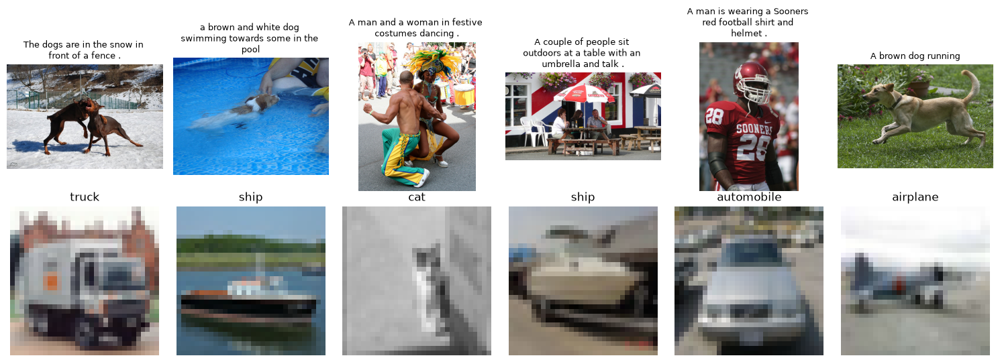

In [4]:
def load_parquet(repo_id, filename):
    return pq.read_table(hf_hub_download(repo_id=repo_id, filename=filename, repo_type="dataset"))

def to_pil(d):
    return Image.open(io.BytesIO(d["bytes"])).convert("RGB")

# Flickr8k: 1000 тестовых фотографий × 5 подписей
f8k = load_parquet("jxie/flickr8k", "data/test-00000-of-00001-42a2661d12c73e48.parquet")
flickr_images = [to_pil(d) for d in f8k.column("image").to_pylist()]
flickr_caps = [[f8k.column(f"caption_{j}")[i].as_py().strip() for j in range(5)] for i in range(f8k.num_rows)]
print("Flickr8k:", len(flickr_images), "изображений,", sum(map(len, flickr_caps)), "подписей")

# CIFAR-10: сбалансированные подвыборки (100 на класс в тесте и 100 на класс для few-shot)
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
def cifar_subset(split, per_class, seed=0):
    t = load_parquet("uoft-cs/cifar10", f"plain_text/{split}-00000-of-00001.parquet")
    y = np.array(t.column("label").to_pylist())
    r = np.random.default_rng(seed)
    idx = np.sort(np.concatenate([r.choice(np.where(y == c)[0], per_class, replace=False) for c in range(10)]))
    imgs = t.column("img").take(idx).to_pylist()
    return [to_pil(d) for d in imgs], y[idx]

cifar_te_img, cifar_te_y = cifar_subset("test", 100)
cifar_tr_img, cifar_tr_y = cifar_subset("train", 100)
print("CIFAR-10: тест", len(cifar_te_img), "| обучение (для few-shot)", len(cifar_tr_img))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for k, ax in enumerate(axes[0]):
    ax.imshow(flickr_images[k]); ax.axis("off"); ax.set_title("\n".join(re.findall(".{1,28}(?:\\s|$)", flickr_caps[k][0])), fontsize=9)
for k, ax in enumerate(axes[1]):
    j = k * 150; ax.imshow(cifar_te_img[j]); ax.axis("off"); ax.set_title(CIFAR_CLASSES[cifar_te_y[j]], fontsize=12)
plt.tight_layout(); plt.show()

In [5]:
t0 = time.time()
flickr_img_emb = encode_images(flickr_images)                          # [1000, 512]
all_caps = [c for caps in flickr_caps for c in caps]                   # 5000 подписей
cap2img = np.repeat(np.arange(len(flickr_caps)), 5)                    # номер изображения для каждой подписи
flickr_txt_emb = encode_texts(all_caps)                                # [5000, 512]
cifar_te_emb = encode_images(cifar_te_img)
cifar_tr_emb = encode_images(cifar_tr_img)
print(f"Эмбеддинги посчитаны за {time.time() - t0:.0f} с:", tuple(flickr_img_emb.shape), tuple(flickr_txt_emb.shape),
      tuple(cifar_te_emb.shape), tuple(cifar_tr_emb.shape))

Эмбеддинги посчитаны за 176 с: (1000, 512) (5000, 512) (1000, 512) (1000, 512)


## 2. Первый пример: свободные текстовые метки

Классы задаются произвольными фразами, без обучения. Модель сравнивает изображение со всеми фразами и превращает косинусные сходства в распределение вероятностей.

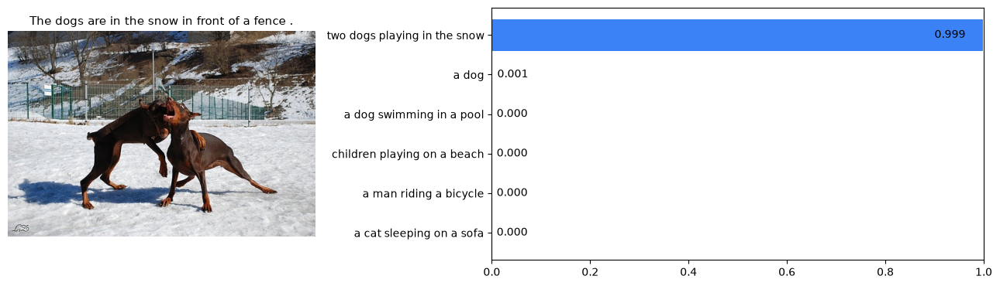

In [6]:
def zero_shot_probs(image_emb, texts):
    t = encode_texts(texts)
    logits = model.logit_scale.exp().item() * image_emb @ t.T
    return logits.softmax(-1)

def show_probs(img, labels, probs, title=""):
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1, 1.6]))
    a.imshow(img); a.axis("off"); a.set_title(title, fontsize=11)
    order = np.argsort(probs)
    b.barh([labels[i] for i in order], probs[order], color="#3b82f6"); b.set_xlim(0, 1)
    for k, i in enumerate(order): b.text(min(probs[i] + 0.01, 0.9), k, f"{probs[i]:.3f}", va="center")
    plt.tight_layout(); plt.show()

labels = ["two dogs playing in the snow", "a dog swimming in a pool", "a cat sleeping on a sofa",
          "a man riding a bicycle", "children playing on a beach", "a dog"]
p = zero_shot_probs(flickr_img_emb[0:1], labels)[0].numpy()
show_probs(flickr_images[0], labels, p, title=flickr_caps[0][0])

Две вещи, которые стоит запомнить с первого примера.

1. Softmax берётся только по предложенным вариантам. Модель не умеет ответить «ничего из перечисленного»: вероятности всегда суммируются в 1, даже если ни одна фраза не подходит.
2. Более точное описание («two dogs playing in the snow») выигрывает у общего («a dog»), хотя оба верны. Поэтому список классов — это часть модели: от того, как он сформулирован, зависит ответ.

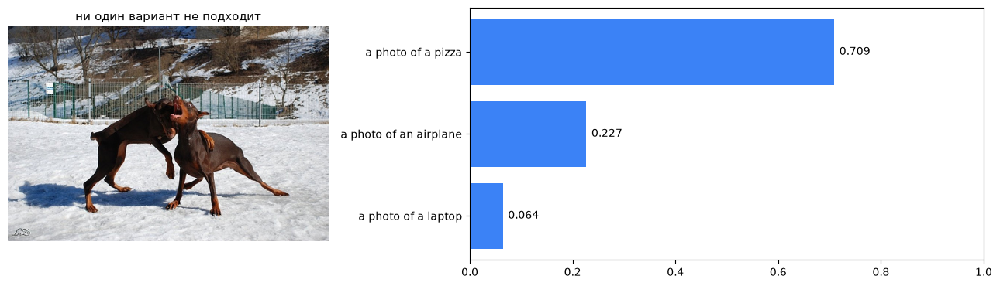

Косинусные сходства (последний — правильное описание): [0.18  0.191 0.167 0.302]


In [7]:
labels_none = ["a photo of an airplane", "a photo of a pizza", "a photo of a laptop"]
p = zero_shot_probs(flickr_img_emb[0:1], labels_none)[0].numpy()
show_probs(flickr_images[0], labels_none, p, title="ни один вариант не подходит")
cos = (flickr_img_emb[0:1] @ encode_texts(labels_none + labels[:1]).T)[0]
print("Косинусные сходства (последний — правильное описание):", np.round(cos.numpy(), 3))

Абсолютные косинусы малы (около 0.15–0.35 даже для верной пары) из-за модального разрыва (раздел 8), но их порядок осмыслен. Для отказа от ответа можно ввести порог на косинус или добавить класс-«фон» вроде «a photo of something else»; оба приёма нужно калибровать на валидации.

## 3. Функция потерь CLIP на реальном батче

Соберём батч из 16 пар (изображение, подпись), посчитаем матрицу сходств и симметричную кросс-энтропию вручную. Затем сравним результат со встроенным расчётом `return_loss=True` в transformers.

Наш расчёт: 0.1236 | transformers: 0.1236
Доля пар, угаданных внутри батча (картинка→текст): 0.875
Потеря при перемешанных подписях: 15.432  (ln N = 2.773)


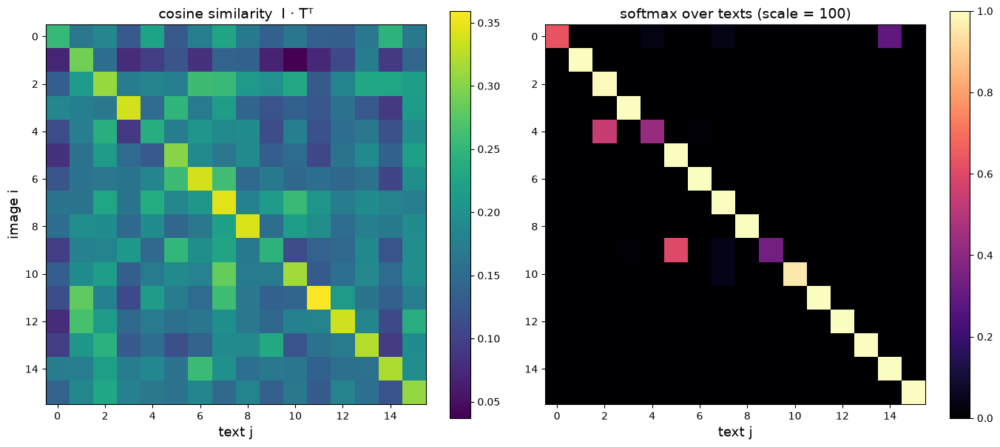

In [8]:
def clip_loss(img_emb, txt_emb, logit_scale):
    """img_emb, txt_emb: [N, d], L2-нормированы; i-я картинка парна i-му тексту."""
    logits = logit_scale * img_emb @ txt_emb.T                 # [N, N]
    labels = torch.arange(len(img_emb))
    loss_i2t = F.cross_entropy(logits, labels)                 # по строкам: картинка → текст
    loss_t2i = F.cross_entropy(logits.T, labels)               # по столбцам: текст → картинка
    return (loss_i2t + loss_t2i) / 2, logits

N = 16
idx = np.arange(0, 1000, 1000 // N)[:N]
I_b, T_b = flickr_img_emb[idx], encode_texts([flickr_caps[i][0] for i in idx])
scale = model.logit_scale.exp().item()
loss, logits = clip_loss(I_b, T_b, scale)

# Проверка: встроенный расчёт transformers
with torch.no_grad():
    px = processor.image_processor(images=[flickr_images[i] for i in idx], return_tensors="pt")["pixel_values"].to(DEVICE)
    tk = tokenizer([flickr_caps[i][0] for i in idx], padding=True, return_tensors="pt").to(DEVICE)
    hf_loss = model(pixel_values=px, **tk, return_loss=True).loss.item()
print(f"Наш расчёт: {loss.item():.4f} | transformers: {hf_loss:.4f}")
print("Доля пар, угаданных внутри батча (картинка→текст):", (logits.argmax(1) == torch.arange(N)).float().mean().item())

shuffled = T_b[torch.randperm(N)]
print(f"Потеря при перемешанных подписях: {clip_loss(I_b, shuffled, scale)[0].item():.3f}  (ln N = {math.log(N):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im = axes[0].imshow((I_b @ T_b.T).numpy(), cmap="viridis"); axes[0].set_title("cosine similarity  I · Tᵀ", fontsize=14)
axes[0].set_xlabel("text j", fontsize=13); axes[0].set_ylabel("image i", fontsize=13); plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(logits.softmax(1).numpy(), cmap="magma", vmin=0, vmax=1)
axes[1].set_title("softmax over texts (scale = 100)", fontsize=14); axes[1].set_xlabel("text j", fontsize=13); plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

Слева видно, что диагональ выделяется лишь немного: косинусы верных пар около 0.3 при фоне около 0.15. Справа те же числа после умножения на 100 и softmax: распределения становятся почти one-hot. Именно для этого нужна обучаемая температура.

При перемешанных подписях потеря становится много больше $\ln N$ — уровня случайного угадывания. Это происходит потому, что модель уверенно ставит большую вероятность «своему» тексту, а он теперь стоит в чужом столбце.

Посмотрим, как масштаб логитов влияет на потерю на тех же данных.

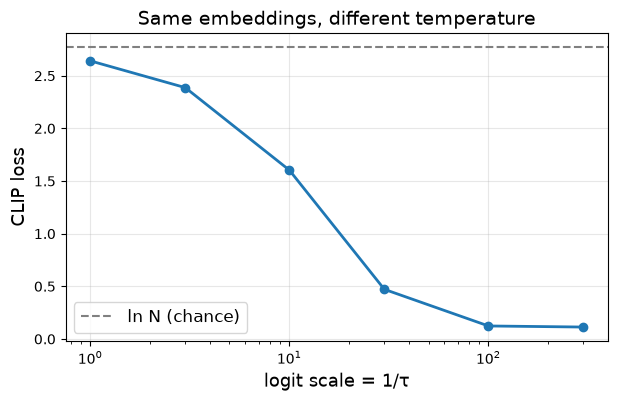

{1: 2.641, 3: 2.387, 10: 1.604, 30: 0.471, 100: 0.124, 300: 0.113}


In [9]:
scales = [1, 3, 10, 30, 100, 300]
vals = [clip_loss(I_b, T_b, s)[0].item() for s in scales]
plt.figure(figsize=(7, 4)); plt.semilogx(scales, vals, "o-", lw=2); plt.axhline(math.log(N), ls="--", c="gray", label="ln N (chance)")
plt.xlabel("logit scale = 1/τ", fontsize=13); plt.ylabel("CLIP loss", fontsize=13); plt.legend(fontsize=12); plt.grid(alpha=.3)
plt.title("Same embeddings, different temperature", fontsize=14); plt.show()
print({s: round(v, 3) for s, v in zip(scales, vals)})

При малом масштабе (высокой температуре) потеря близка к $\ln N$ даже для хороших эмбеддингов: все косинусы лежат в узком диапазоне, и softmax почти равномерен. Чем выше масштаб, тем ниже потеря, пока верные пары остаются наибольшими в строке.

В нашем прогоне потеря падает монотонно: примерно 2.64 при масштабе 1, 0.12 при 100 и 0.11 при 300. После 100 выигрыш уже мал, а каждая ошибка ранжирования при большом масштабе штрафуется всё сильнее, и градиенты становятся резкими. Поэтому авторы обучают температуру, но ограничивают масштаб значением 100, чтобы не дестабилизировать обучение ([Radford et al., разд. 2.5](https://arxiv.org/abs/2103.00020)).

## 4. Zero-shot-классификация CIFAR-10

Классификатор строится из текста: для каждого класса берём эмбеддинги промптов, усредняем их и нормируем. Сравним три варианта:

- голое имя класса;
- шаблон «a photo of a {}.»;
- ансамбль из 18 шаблонов, которые OpenAI использовала для CIFAR-10 ([CLIP/data/prompts.md](https://github.com/openai/CLIP/blob/main/data/prompts.md)).

In [10]:
CIFAR_TEMPLATES = [
    'a photo of a {}.', 'a blurry photo of a {}.', 'a black and white photo of a {}.', 'a low contrast photo of a {}.',
    'a high contrast photo of a {}.', 'a bad photo of a {}.', 'a good photo of a {}.', 'a photo of a small {}.',
    'a photo of a big {}.', 'a photo of the {}.', 'a blurry photo of the {}.', 'a black and white photo of the {}.',
    'a low contrast photo of the {}.', 'a high contrast photo of the {}.', 'a bad photo of the {}.',
    'a good photo of the {}.', 'a photo of the small {}.', 'a photo of the big {}.']

def zeroshot_classifier(classnames, templates, encode=encode_texts):
    W = []
    for c in classnames:
        e = encode([t.format(c) for t in templates])          # [T, d]
        W.append(F.normalize(e.mean(0), dim=-1))               # ансамбль в пространстве эмбеддингов
    return torch.stack(W)                                      # [C, d]

def accuracy_ci(pred, y):
    a = float((pred == y).mean()); se = math.sqrt(a * (1 - a) / len(y))
    return a, se

variants = {"class name only": ["{}"], "'a photo of a {}.'": ["a photo of a {}."], "ensemble of 18 templates": CIFAR_TEMPLATES}
zs = {}
for name, tmpl in variants.items():
    W = zeroshot_classifier(CIFAR_CLASSES, tmpl)
    logits = 100.0 * cifar_te_emb @ W.T
    zs[name] = dict(W=W, logits=logits)
    a, se = accuracy_ci(logits.argmax(1).numpy(), cifar_te_y)
    print(f"{name:28s} accuracy = {100 * a:.1f} ± {100 * 1.96 * se:.1f} %  (95% ДИ, n = {len(cifar_te_y)})")

class name only              accuracy = 86.8 ± 2.1 %  (95% ДИ, n = 1000)


'a photo of a {}.'           accuracy = 88.9 ± 1.9 %  (95% ДИ, n = 1000)


ensemble of 18 templates     accuracy = 90.0 ± 1.9 %  (95% ДИ, n = 1000)


Для сравнения: в статье ViT-B/32 даёт на полном тесте CIFAR-10 (10 000 изображений) 91.3% zero-shot ([Radford et al., табл. 11](https://arxiv.org/abs/2103.00020)). На нашей подвыборке из 1000 изображений доверительный интервал около ±2 п.п., поэтому по одним интервалам нельзя сказать, надёжна ли разница в 1 п.п. между вариантами промптов. В нашем прогоне на CPU получилось 86.8% для голого имени класса, 88.9% для одного шаблона и 90.0% для ансамбля; на GPU в float16 числа могут отличаться на десятые доли. Для честного сравнения нужен полный тест или парный тест на одних и тех же изображениях (ниже). Парный тест Мак-Немара учитывает только изображения, на которых варианты расходятся, и поэтому чувствительнее: в нашем прогоне он дал p ≈ 0.035 в пользу ансамбля.

только шаблон прав: 6 | только ансамбль прав: 17 | оба правы: 883
Точный тест Мак-Немара: p = 0.035


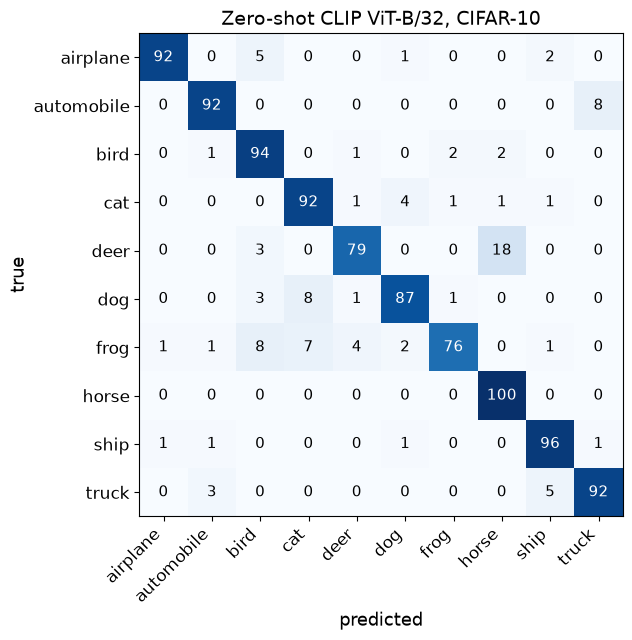

In [11]:
# Парное сравнение: на скольких изображениях варианты расходятся и кто прав
a = zs["'a photo of a {}.'"]["logits"].argmax(1).numpy() == cifar_te_y
b = zs["ensemble of 18 templates"]["logits"].argmax(1).numpy() == cifar_te_y
print("только шаблон прав:", int((a & ~b).sum()), "| только ансамбль прав:", int((~a & b).sum()), "| оба правы:", int((a & b).sum()))
from math import comb
n01, n10 = int((a & ~b).sum()), int((~a & b).sum()); n = n01 + n10
p_mcnemar = min(1.0, 2 * sum(comb(n, k) for k in range(0, min(n01, n10) + 1)) / 2 ** n) if n else 1.0
print(f"Точный тест Мак-Немара: p = {p_mcnemar:.3f}")

# Матрица ошибок для ансамбля
from sklearn.metrics import confusion_matrix
pred = zs["ensemble of 18 templates"]["logits"].argmax(1).numpy()
cm = confusion_matrix(cifar_te_y, pred)
plt.figure(figsize=(7.5, 6.5)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CIFAR_CLASSES, rotation=45, ha="right", fontsize=12); plt.yticks(range(10), CIFAR_CLASSES, fontsize=12)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 50 else "black", fontsize=11)
plt.xlabel("predicted", fontsize=13); plt.ylabel("true", fontsize=13); plt.title("Zero-shot CLIP ViT-B/32, CIFAR-10", fontsize=14)
plt.tight_layout(); plt.show()

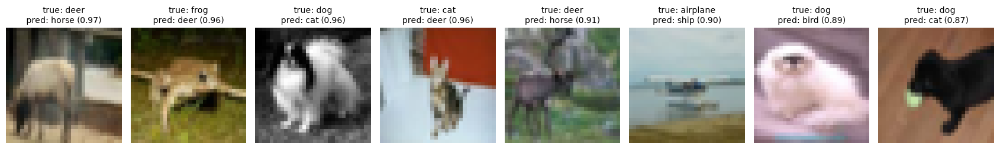

In [12]:
# Самые уверенные ошибки: часто это неоднозначные снимки 32×32 или ошибки разметки
probs = zs["ensemble of 18 templates"]["logits"].softmax(1).numpy()
wrong = np.where(pred != cifar_te_y)[0]
worst = wrong[np.argsort(-probs[wrong].max(1))][:8]
fig, axes = plt.subplots(1, 8, figsize=(17, 3))
for ax, i in zip(axes, worst):
    ax.imshow(cifar_te_img[i]); ax.axis("off")
    ax.set_title(f"true: {CIFAR_CLASSES[cifar_te_y[i]]}\npred: {CIFAR_CLASSES[pred[i]]} ({probs[i].max():.2f})", fontsize=10)
plt.tight_layout(); plt.show()

### Имя класса — тоже гиперпараметр

Названия классов в датасетах выбирались не для текстового энкодера. Заменим «automobile» на «car» и посмотрим, что изменится на этом классе. Это легитимно: мы меняем описание задачи, а не подглядываем в тестовые метки. Но выбирать имена нужно на валидации, а не на тесте.

In [13]:
def per_class_acc(classnames, templates=CIFAR_TEMPLATES):
    W = zeroshot_classifier(classnames, templates)
    p = (cifar_te_emb @ W.T).argmax(1).numpy()
    return np.array([(p[cifar_te_y == c] == c).mean() for c in range(10)]), (p == cifar_te_y).mean()

base_pc, base_acc = per_class_acc(CIFAR_CLASSES)
alt = CIFAR_CLASSES.copy(); alt[1] = "car"
alt_pc, alt_acc = per_class_acc(alt)
print(f"automobile → car: точность класса {100 * base_pc[1]:.0f}% → {100 * alt_pc[1]:.0f}%, общая {100 * base_acc:.1f}% → {100 * alt_acc:.1f}%")

automobile → car: точность класса 92% → 89%, общая 90.0% → 90.0%


В нашем прогоне замена «automobile» на «car» не помогла: точность класса снизилась с 92% до 89%, общая точность не изменилась. Интуиция «более частое слово лучше» не гарантирует улучшения, поэтому любые замены имён нужно проверять измерением.

### Калибровка вероятностей

Обученный масштаб 100 подобран для обучающей задачи «выбери 1 из 32 768 текстов», а не для вашей 10-классовой задачи. Проверим, насколько вероятности zero-shot-классификатора соответствуют реальной частоте правильных ответов. Мера — Expected Calibration Error (ECE) по 10 корзинам уверенности:

$$
\mathrm{ECE}=\sum_{b=1}^{B}\frac{|S_b|}{n}\,\big|\mathrm{acc}(S_b)-\mathrm{conf}(S_b)\big|.
$$

Температуру подберём на половине теста и проверим на второй половине (temperature scaling).

In [14]:
def ece(probs, y, bins=10):
    conf, pred = probs.max(1), probs.argmax(1); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

cos_te = (cifar_te_emb @ zs["ensemble of 18 templates"]["W"].T).numpy()
r = np.random.default_rng(0); perm = r.permutation(len(cifar_te_y)); cal, ev = perm[:500], perm[500:]
def nll(s, ix):
    z = s * cos_te[ix]; z = z - z.max(1, keepdims=True)
    return -(z[np.arange(len(ix)), cifar_te_y[ix]] - np.log(np.exp(z).sum(1))).mean()
grid = np.linspace(5, 300, 300); best_s = grid[np.argmin([nll(s, cal) for s in grid])]
softmax = lambda z: np.exp(z - z.max(1, keepdims=True)) / np.exp(z - z.max(1, keepdims=True)).sum(1, keepdims=True)
for s, name in [(100.0, "обученный масштаб 100"), (best_s, f"подобранный масштаб {best_s:.0f}")]:
    print(f"{name:28s} ECE на отложенной половине = {ece(softmax(s * cos_te[ev]), cifar_te_y[ev]):.3f}")

обученный масштаб 100        ECE на отложенной половине = 0.054
подобранный масштаб 131      ECE на отложенной половине = 0.029


В нашем прогоне подобранный масштаб (около 131) оказался больше обученного: на CIFAR-10 zero-shot-классификатор слегка недоуверен, и ECE снизилась примерно с 0.054 до 0.029. На другом домене поправка может пойти в обратную сторону.

Temperature scaling не меняет argmax, а значит, и точность, — он меняет только уверенность. Если вероятности CLIP используются для порогов, отказа от ответа или авторазметки (лекция 7 курса), калибровать их нужно на данных своего домена.

## 5. Zero-shot против few-shot

В статье zero-shot CLIP в среднем по 20 датасетам соответствует логистической регрессии, обученной на 4 примерах на класс в том же пространстве признаков ([Radford et al., рис. 6](https://arxiv.org/abs/2103.00020)). Проверим на CIFAR-10. Сравниваются три способа:

1. Linear probe: логистическая регрессия на $k$ размеченных примерах на класс.
2. Zero-shot: текстовый классификатор из раздела 4, разметка не нужна.
3. Комбинация в духе [Tip-Adapter](https://arxiv.org/abs/2111.03930), без обучения. К zero-shot-логитам добавляется «кэш»-классификатор: сходство с размеченными примерами, переведённое в голоса их классов.
$$
\text{logits}(f)=100\,fW^\top+\alpha\,\exp\!\big(-\beta\,(1-fF_{\text{train}}^\top)\big)\,L_{\text{train}},
$$
   где $F_{\text{train}}$ — эмбеддинги размеченных примеров, $L_{\text{train}}$ — их one-hot-метки. Мы берём $\alpha=1$, $\beta=5$; в реальной задаче их подбирают на валидации.

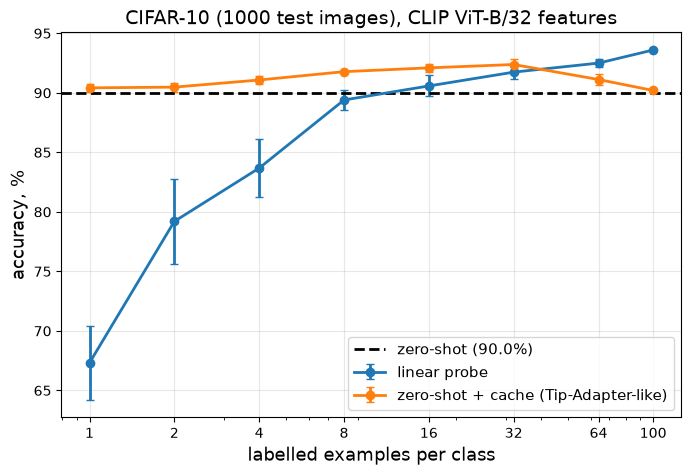

k=  1: linear probe  67.3 ± 3.1 | zero-shot + cache  90.4 ± 0.3
k=  2: linear probe  79.2 ± 3.5 | zero-shot + cache  90.5 ± 0.4
k=  4: linear probe  83.7 ± 2.4 | zero-shot + cache  91.1 ± 0.3
k=  8: linear probe  89.4 ± 0.9 | zero-shot + cache  91.8 ± 0.1
k= 16: linear probe  90.6 ± 0.9 | zero-shot + cache  92.1 ± 0.3
k= 32: linear probe  91.7 ± 0.6 | zero-shot + cache  92.4 ± 0.5
k= 64: linear probe  92.5 ± 0.3 | zero-shot + cache  91.1 ± 0.5
k=100: linear probe  93.6 ± 0.0 | zero-shot + cache  90.2 ± 0.0


In [15]:
from sklearn.linear_model import LogisticRegression
W_zs = zs["ensemble of 18 templates"]["W"]
zs_acc = float(((cifar_te_emb @ W_zs.T).argmax(1).numpy() == cifar_te_y).mean())
Xtr, Xte = cifar_tr_emb.numpy(), cifar_te_emb.numpy()

def tip_adapter(Fs, ys, alpha=1.0, beta=5.0):
    L = np.eye(10)[ys]
    A = np.exp(-beta * (1 - Xte @ Fs.T)) @ L
    return (100 * Xte @ W_zs.numpy().T + alpha * A).argmax(1)

shots, seeds, res = [1, 2, 4, 8, 16, 32, 64, 100], 5, {"linear probe": [], "zero-shot + cache (Tip-Adapter-like)": []}
for k in shots:
    lp, tip = [], []
    for s in range(seeds if k < 100 else 1):
        r = np.random.default_rng(s)
        sel = np.concatenate([r.choice(np.where(cifar_tr_y == c)[0], k, replace=False) for c in range(10)])
        clf = LogisticRegression(max_iter=3000, C=10.0).fit(Xtr[sel], cifar_tr_y[sel])
        lp.append(clf.score(Xte, cifar_te_y)); tip.append((tip_adapter(Xtr[sel], cifar_tr_y[sel]) == cifar_te_y).mean())
    res["linear probe"].append((np.mean(lp), np.std(lp))); res["zero-shot + cache (Tip-Adapter-like)"].append((np.mean(tip), np.std(tip)))

plt.figure(figsize=(8, 5))
for name, v in res.items():
    m, s = np.array(v).T * 100
    plt.errorbar(shots, m, yerr=s, marker="o", capsize=3, lw=2, label=name)
plt.axhline(100 * zs_acc, color="k", ls="--", lw=2, label=f"zero-shot ({100 * zs_acc:.1f}%)")
plt.xscale("log"); plt.xticks(shots, shots); plt.xlabel("labelled examples per class", fontsize=13); plt.ylabel("accuracy, %", fontsize=13)
plt.title("CIFAR-10 (1000 test images), CLIP ViT-B/32 features", fontsize=14); plt.legend(fontsize=11); plt.grid(alpha=.3); plt.show()
for k, (m1, s1), (m2, s2) in zip(shots, res["linear probe"], res["zero-shot + cache (Tip-Adapter-like)"]):
    print(f"k={k:3d}: linear probe {100 * m1:5.1f} ± {100 * s1:.1f} | zero-shot + cache {100 * m2:5.1f} ± {100 * s2:.1f}")

Как читать график:

- При 1–2 примерах на класс линейный классификатор заметно хуже zero-shot. Один пример не говорит, какой из многих визуальных признаков важен, а текст говорит это прямо. В статье это объясняется так же ([Radford et al., разд. 3.1.5](https://arxiv.org/abs/2103.00020)).
- С ростом разметки linear probe догоняет и обгоняет zero-shot: признаки CLIP содержат больше, чем извлекает текстовый классификатор. В статье linear probe ViT-B/32 на полном CIFAR-10 даёт 95.1% против 91.3% zero-shot ([табл. 10 и 11](https://arxiv.org/abs/2103.00020)).
- Комбинация не опускается ниже zero-shot при малом числе примеров и использует разметку, когда она есть. В нашем прогоне она лучше всех при 1–16 примерах на класс (90.4–92.1%). При 64–100 примерах её обгоняет linear probe (92.5–93.6%): с фиксированными $\alpha=1$, $\beta=5$ кэш из многих примеров начинает шуметь, поэтому эти гиперпараметры подбирают на валидации. Это практический рецепт для курсового проекта: начинать с zero-shot и добавлять размеченные примеры как кэш или линейную голову, инициализированную текстом.

## 6. Мультимодальный поиск на Flickr8k

Индекс — 1000 эмбеддингов изображений, запросы — 5000 подписей. Метрики:

- Text → image, Recall@K: доля подписей, для которых их изображение попало в top-K.
- Image → text, Recall@K: доля изображений, для которых хотя бы одна из 5 их подписей попала в top-K.

Авторы CLIP добавляли к подписи префикс «a photo of» и сообщают, что это повышает R@1 на 1–2 пункта ([Radford et al., прил. E.1](https://arxiv.org/abs/2103.00020)). Проверим это.

In [16]:
def retrieval_metrics(img_emb, txt_emb, cap2img, ks=(1, 5, 10)):
    S = txt_emb @ img_emb.T                                         # [n_txt, n_img]
    # text → image: позиция правильного изображения
    gt = S[torch.arange(len(cap2img)), torch.as_tensor(cap2img)]
    rank_t2i = (S > gt[:, None]).sum(1).numpy()                     # 0 = на первом месте
    # image → text: лучшая позиция среди 5 подписей
    St = S.T
    rank_i2t = np.full(len(img_emb), 10 ** 9)
    order = torch.argsort(St, dim=1, descending=True).numpy()
    for i in range(len(img_emb)):
        pos = np.where(cap2img[order[i]] == i)[0]
        rank_i2t[i] = pos.min()
    out = {f"T→I R@{k}": 100 * (rank_t2i < k).mean() for k in ks}
    out.update({f"I→T R@{k}": 100 * (rank_i2t < k).mean() for k in ks})
    out["T→I MRR"] = float((1 / (rank_t2i + 1)).mean())
    return out, rank_t2i

def lower_first(s): return s[0].lower() + s[1:] if s else s
txt_emb_prefix = encode_texts(["a photo of " + lower_first(c) for c in all_caps])

m_plain, rank_plain = retrieval_metrics(flickr_img_emb, flickr_txt_emb, cap2img)
m_pref, rank_pref = retrieval_metrics(flickr_img_emb, txt_emb_prefix, cap2img)
print(f"{'':16s}" + "".join(f"{k:>11s}" for k in m_plain))
for name, m in [("caption", m_plain), ("'a photo of' + c", m_pref)]:
    print(f"{name:16s}" + "".join(f"{v:11.3f}" if 'MRR' in k else f"{v:11.1f}" for k, v in m.items()))

                    T→I R@1    T→I R@5   T→I R@10    I→T R@1    I→T R@5   I→T R@10    T→I MRR
caption                53.8       80.8       88.9       71.1       91.9       95.7      0.659
'a photo of' + c       55.0       81.4       89.0       72.2       92.0       96.5      0.668


Ориентиры. Это 1000 изображений Flickr8k и ViT-B/32. В статье на 1000 изображениях Flickr30k лучшая модель (ViT-L/14@336px) даёт R@1 88.0% для image→text и 68.7% для text→image ([табл. 13](https://arxiv.org/abs/2103.00020)). На 5000 изображений MS-COCO — 58.4% и 37.8%. Задача тем труднее, чем больше индекс: на COCO в 5 раз больше кандидатов.

### Поиск по произвольному запросу

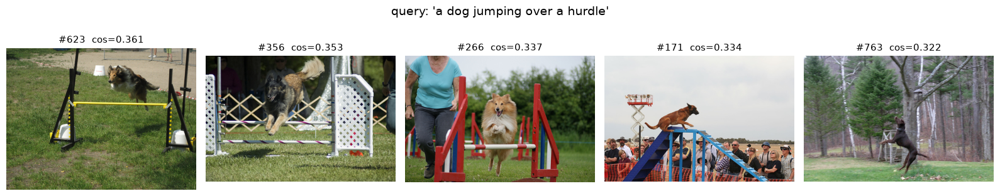

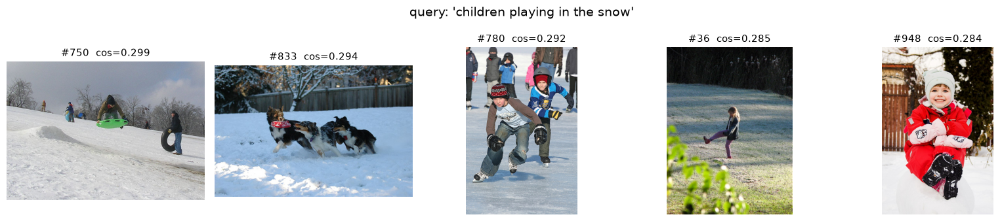

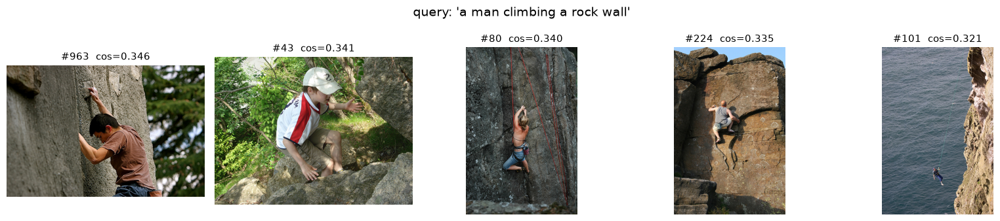

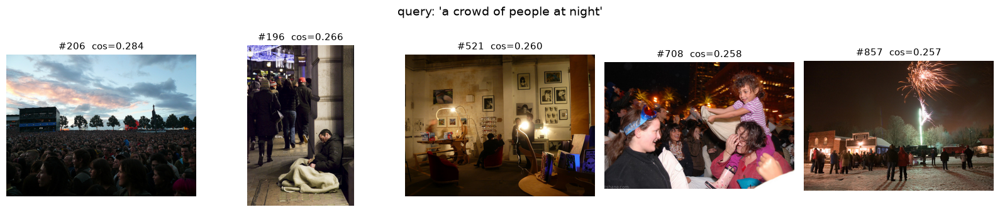

In [17]:
def search_text(query, k=5, prefix=True):
    q = encode_texts([("a photo of " + query) if prefix else query])
    s = (flickr_img_emb @ q.T)[:, 0]
    top = torch.topk(s, k)
    return top.indices.numpy(), top.values.numpy()

def show_results(idxs, scores, title):
    fig, axes = plt.subplots(1, len(idxs), figsize=(3.2 * len(idxs), 3.4))
    for ax, i, s in zip(axes, idxs, scores):
        ax.imshow(flickr_images[i]); ax.axis("off"); ax.set_title(f"#{i}  cos={s:.3f}", fontsize=11)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

for q in ["a dog jumping over a hurdle", "children playing in the snow", "a man climbing a rock wall",
          "a crowd of people at night"]:
    show_results(*search_text(q), title=f"query: {q!r}")

### Поиск по изображению и составные запросы

В общем пространстве можно искать похожие изображения (image → image) и сдвигать запрос текстом. Поскольку эмбеддинги нормированы, сумма $\mathrm{norm}(f_{\text{img}}+\lambda f_{\text{text}})$ — это направление «между» картинкой и текстом. Такие запросы описаны, например, в [ALIGN](https://arxiv.org/abs/2102.05918). Это эвристика, а не гарантированная операция.

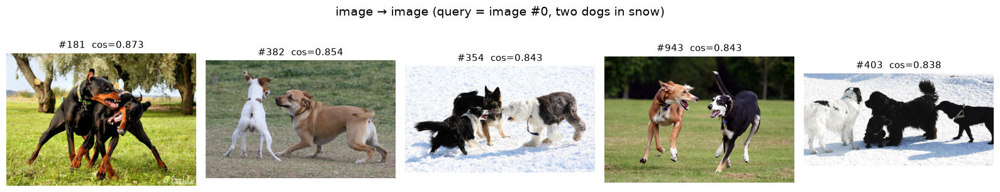

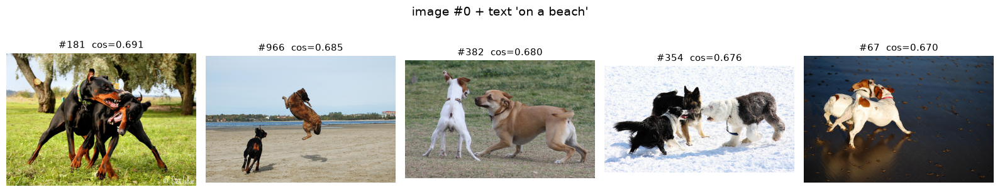

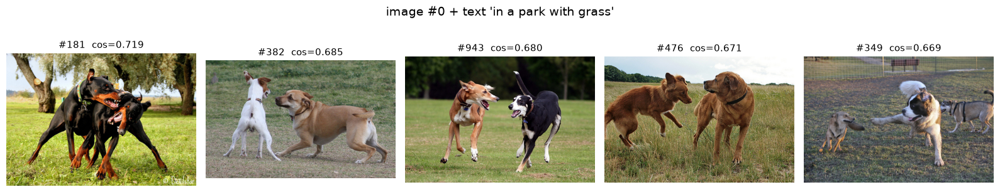

In [18]:
q_id = 0   # две собаки в снегу
s = (flickr_img_emb @ flickr_img_emb[q_id:q_id + 1].T)[:, 0]; s[q_id] = -1
top = torch.topk(s, 5); show_results(top.indices.numpy(), top.values.numpy(), title="image → image (query = image #0, two dogs in snow)")

for text, lam in [("on a beach", 1.0), ("in a park with grass", 1.0)]:
    q = F.normalize(flickr_img_emb[q_id] + lam * encode_texts(["a photo of " + text])[0], dim=-1)
    s = flickr_img_emb @ q; s[q_id] = -1
    top = torch.topk(s, 5); show_results(top.indices.numpy(), top.values.numpy(), title=f"image #0 + text {text!r}")

### Отрицание: слабое место dual encoder

Сравним запросы «собака в воде» и «собака не в воде». Мерой будет доля top-20 результатов, у которых хотя бы одна из 5 эталонных подписей упоминает воду.

In [19]:
WATER = re.compile(r"\b(water|pool|lake|river|ocean|sea|swim\w*|splash\w*|wave\w*|stream|surf\w*)\b", re.I)
def water_share(query, k=20):
    idxs, _ = search_text(query, k=k)
    return np.mean([any(WATER.search(c) for c in flickr_caps[i]) for i in idxs])
base_rate = np.mean([any(WATER.search(c) for c in caps) for caps in flickr_caps])
for q in ["a dog in the water", "a dog that is not in the water", "a dog on dry land"]:
    print(f"{q!r:38s} доля 'водных' изображений в top-20: {water_share(q):.2f}")
print(f"для справки: доля таких изображений во всём наборе {base_rate:.2f}")

'a dog in the water'                   доля 'водных' изображений в top-20: 1.00
'a dog that is not in the water'       доля 'водных' изображений в top-20: 1.00
'a dog on dry land'                    доля 'водных' изображений в top-20: 0.95
для справки: доля таких изображений во всём наборе 0.21


В нашем прогоне запрос с «not» вернул столько же «водных» изображений (100% top-20), сколько запрос без отрицания, при доле таких изображений в наборе 21%. Текстовый эмбеддинг ведёт себя скорее как мешок значимых слов («dog», «water»), чем как логическая формула.

Переформулирование без отрицания («on dry land») здесь тоже не помогло: 95% top-20 — снова «водные» сцены. Слово «land» в подписях Flickr8k чаще всего встречается рядом с пляжами и берегами, а наша мера грубая: регулярное выражение отмечает изображение, если хотя бы одна из 5 подписей упоминает воду, волны или пляжный сёрфинг. Вывод: реформулировка запроса — эвристика, её эффект нужно измерять. Надёжнее отфильтровать «водные» результаты вторым запросом, то есть исключить изображения, близкие к «a dog in the water».

Это частный случай общей проблемы композиционности (теоретическая часть, раздел 7).

### Анализ ошибок поиска

запрос: 'The woman on the right is wearing a red scarf .'  → правильное изображение #529 на месте 261


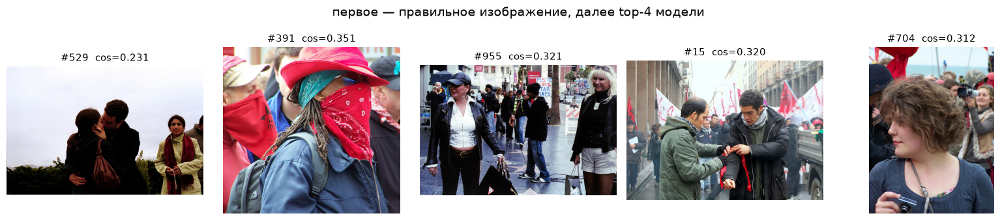

запрос: 'Some kids play outside on a nice day .'  → правильное изображение #301 на месте 254


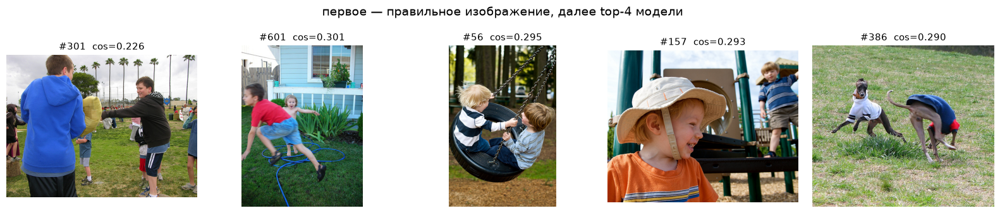

запрос: 'A dog walking through the pound .'  → правильное изображение #939 на месте 213


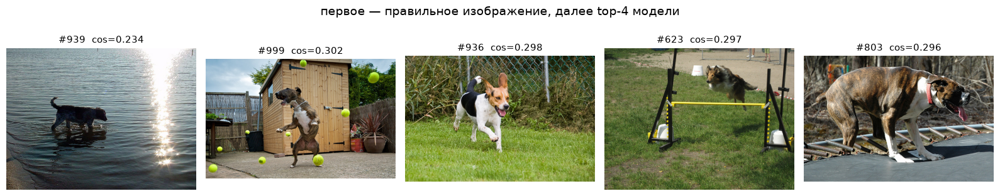

In [20]:
worst_caps = np.argsort(-rank_pref)[:3]
for c in worst_caps:
    print(f"запрос: {all_caps[c]!r}  → правильное изображение #{cap2img[c]} на месте {rank_pref[c] + 1}")
    idxs, sc = search_text(lower_first(all_caps[c]), k=4)
    show_results(np.r_[cap2img[c], idxs], np.r_[float(txt_emb_prefix[c] @ flickr_img_emb[cap2img[c]]), sc],
                 title="первое — правильное изображение, далее top-4 модели")

Часто «ошибки» на деле не ошибки. Найденное изображение подходит под запрос не хуже эталонного, а эталон один лишь потому, что подпись писали к конкретной фотографии. Recall@K с одним эталоном занижает качество поиска в больших коллекциях. Поэтому в серьёзной оценке часть результатов размечают вручную или используют несколько эталонов.

## 7. Масштабирование поиска: память и скорость

Для $M$ изображений индекс занимает $M\times d$ чисел. При $d=512$ и float16 это 1 КБ на изображение, то есть около 1 ГБ на миллион. Точный поиск — одно матричное умножение. Для миллионов и миллиардов векторов используют приближённый поиск ближайших соседей (ANN): [FAISS](https://github.com/facebookresearch/faiss), HNSW и т. п. Ячейка ниже измеряет точный поиск на синтетическом индексе.

In [21]:
M = 200_000 if DEVICE == "cpu" else 2_000_000
index = F.normalize(torch.randn(M, 512, device=DEVICE), dim=-1).half() if DEVICE == "cuda" else F.normalize(torch.randn(M, 512), dim=-1)
queries = F.normalize(torch.randn(64, 512, device=index.device), dim=-1).to(index.dtype)
t0 = time.time()
for _ in range(5):
    top = torch.topk(queries @ index.T, 10, dim=1)
if DEVICE == "cuda": torch.cuda.synchronize()
dt = (time.time() - t0) / 5
print(f"Точный поиск: {M:,} векторов, 64 запроса за {1000 * dt:.1f} мс ({1000 * dt / 64:.2f} мс на запрос); "
      f"индекс {index.element_size() * index.numel() / 2 ** 20:.0f} МБ")
del index

Точный поиск: 200,000 векторов, 64 запроса за 107.8 мс (1.68 мс на запрос); индекс 391 МБ


Для учебных и большинства курсовых задач (до миллиона изображений) точного поиска на GPU достаточно. ANN нужен при десятках миллионов векторов или жёстких требованиях к задержке на CPU.

## 8. Модальный разрыв и геометрия пространства

[Liang et al.](https://arxiv.org/abs/2203.02053) показали, что в CLIP изображения и тексты лежат в двух разнесённых областях общего пространства (modality gap). Измерим это на Flickr8k.

cos(image, its caption)   = 0.318
cos(image, other caption) = 0.172
cos(image, image)         = 0.517  | cos(text, text) = 0.505
‖mean(image) − mean(text)‖ = 0.823


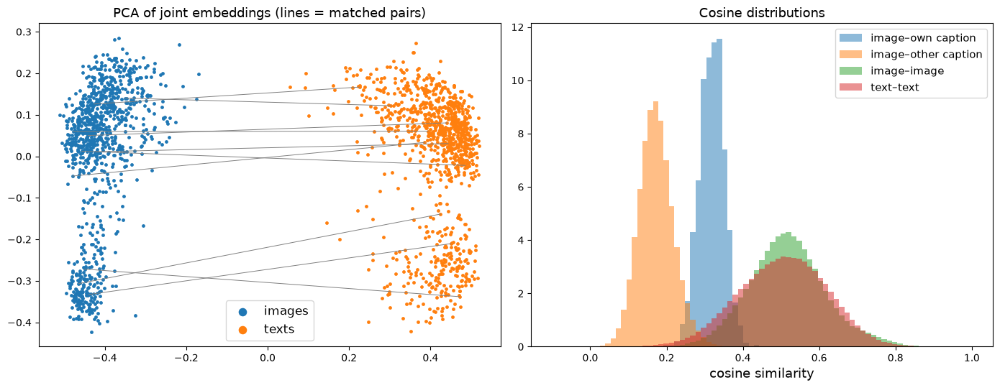

In [22]:
I, T = flickr_img_emb, flickr_txt_emb[::5]                                 # 1000 изображений и по одной подписи к каждому
pos = (I * T).sum(1)                                                      # верные пары
neg = (I @ T.T)[~torch.eye(len(I), dtype=bool)]                           # неверные пары
ii = (I @ I.T)[~torch.eye(len(I), dtype=bool)]; tt = (T @ T.T)[~torch.eye(len(T), dtype=bool)]
gap = I.mean(0) - T.mean(0)
print(f"cos(image, its caption)   = {pos.mean():.3f}")
print(f"cos(image, other caption) = {neg.mean():.3f}")
print(f"cos(image, image)         = {ii.mean():.3f}  | cos(text, text) = {tt.mean():.3f}")
print(f"‖mean(image) − mean(text)‖ = {gap.norm():.3f}")

from sklearn.decomposition import PCA
Z = PCA(2, random_state=0).fit_transform(torch.cat([I, T]).numpy())
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(*Z[:1000].T, s=6, label="images"); axes[0].scatter(*Z[1000:].T, s=6, label="texts")
for k in range(0, 1000, 100): axes[0].plot([Z[k, 0], Z[1000 + k, 0]], [Z[k, 1], Z[1000 + k, 1]], c="gray", lw=.7)
axes[0].legend(fontsize=12, markerscale=3); axes[0].set_title("PCA of joint embeddings (lines = matched pairs)", fontsize=13)
bins = np.linspace(-0.1, 1, 80)
for v, lab in [(pos, "image–own caption"), (neg, "image–other caption"), (ii, "image–image"), (tt, "text–text")]:
    axes[1].hist(v.numpy(), bins=bins, density=True, alpha=.5, label=lab)
axes[1].legend(fontsize=11); axes[1].set_xlabel("cosine similarity", fontsize=13); axes[1].set_title("Cosine distributions", fontsize=13)
plt.tight_layout(); plt.show()

Картина типичная.

- Две модальности образуют два отдельных «облака», разнесённых по первой главной компоненте.
- Косинус картинки с картинкой и текста с текстом заметно выше, чем косинус картинки со своей подписью. Поиск работает не за счёт абсолютной близости, а за счёт порядка: своя подпись ближе чужих.

Практические следствия:

1. Пороги на абсолютный косинус между модальностями (например, «сходство > 0.5 — совпадение») не переносятся между моделями и обычно бессмысленны. Порог калибруют по распределениям верных и неверных пар на своих данных.
2. Смешивать в одном индексе изображения и тексты нельзя без поправок: тексты будут ближе к текстам.
3. Простой приём — центрирование по модальностям: из эмбеддингов вычитается среднее своей модальности, затем выполняется повторная нормировка. Проверим, как центрирование влияет на поиск. Средние считаются по тем же данным, так что это оптимистичная оценка; в реальной системе средние берут с отдельной выборки.

In [23]:
def center(x, mu): return F.normalize(x - mu, dim=-1)
mu_i, mu_t = flickr_img_emb.mean(0), txt_emb_prefix.mean(0)
m_c, _ = retrieval_metrics(center(flickr_img_emb, mu_i), center(txt_emb_prefix, mu_t), cap2img)
for k in ["T→I R@1", "T→I R@5", "I→T R@1", "I→T R@5"]:
    print(f"{k}: без центрирования {m_pref[k]:.1f} | с центрированием {m_c[k]:.1f}")

T→I R@1: без центрирования 55.0 | с центрированием 55.9
T→I R@5: без центрирования 81.4 | с центрированием 82.0
I→T R@1: без центрирования 72.2 | с центрированием 69.9
I→T R@5: без центрирования 92.0 | с центрированием 91.0


В нашем прогоне центрирование немного улучшило text → image (R@1 55.0 → 55.9) и ухудшило image → text (72.2 → 69.9). Ранжирование text → image для одного запроса от центрирования изображений почти не зависит. Сдвиг всех изображений на один вектор меняет все оценки одного запроса одинаково с точностью до перенормировки. Эффект проявляется в основном там, где сравниваются оценки разных запросов или разных модальностей. Это хорошая иллюстрация того, что «исправление» геометрии нужно проверять измерением, а не принимать на веру.

### Хабы

В пространствах высокой размерности некоторые точки оказываются ближайшими соседями непропорционально многих запросов — это «хабы». Посчитаем, сколько раз каждое изображение попадает в top-1 по 5000 текстовым запросам.

In [24]:
top1 = (txt_emb_prefix @ flickr_img_emb.T).argmax(1).numpy()
counts = np.bincount(top1, minlength=1000)
print(f"В идеале каждое изображение — top-1 для 5 запросов. Фактически: максимум {counts.max()}, "
      f"никогда не выигрывают {(counts == 0).sum()} изображений из 1000")
for i in np.argsort(-counts)[:3]:
    print(f"  хаб #{i}: {counts[i]} раз; его подпись: {flickr_caps[i][0]!r}")

В идеале каждое изображение — top-1 для 5 запросов. Фактически: максимум 72, никогда не выигрывают 105 изображений из 1000
  хаб #451: 72 раз; его подпись: 'a lone surfboarder jumping a wave on a white surfboard .'
  хаб #526: 57 раз; его подпись: 'The two white dogs are playing in a field .'
  хаб #941: 38 раз; его подпись: 'A man in a black hoodie and jeans skateboards down a railing .'


## 9. Ограничения CLIP на практике

### 9.1. Типографская атака

Исследователи OpenAI обнаружили, что CLIP «читает» текст на изображении: яблоко с бумажкой «iPod» классифицируется как iPod ([Goh et al., Distill](https://distill.pub/2021/multimodal-neurons/)). Воспроизведём это на оригинальных изображениях OpenAI с тем же набором меток, что в [руководстве AutoGluon](https://auto.gluon.ai/stable/tutorials/multimodal/image_prediction/clip_zeroshot.html).

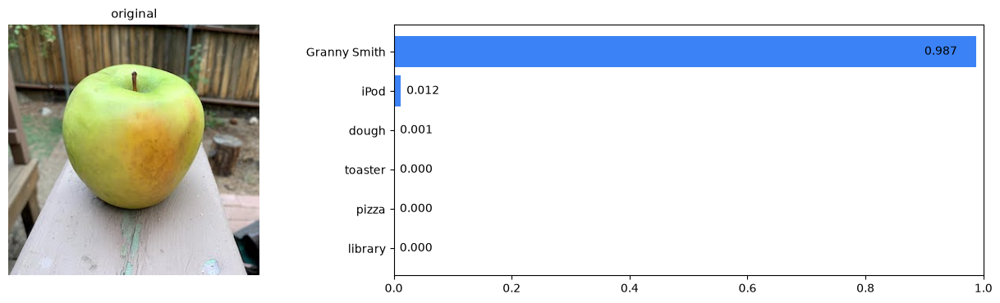

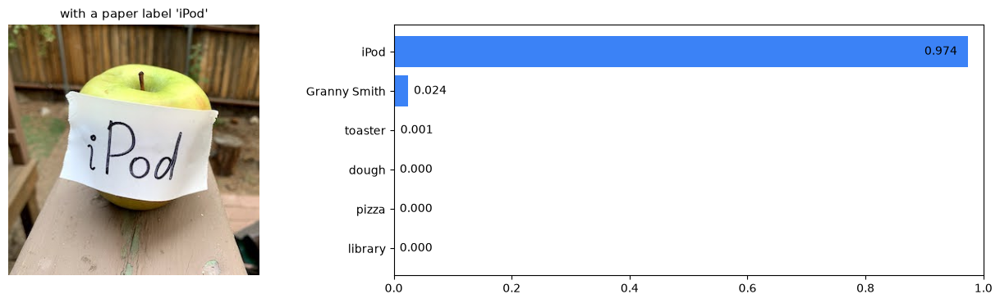

In [25]:
def get_image(url):
    try:
        r = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0"}); r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    except Exception as e:
        print("не удалось загрузить", url, e); return None

apple = get_image("https://cdn.openai.com/multimodal-neurons/assets/apple/apple-blank.jpg")
apple_ipod = get_image("https://cdn.openai.com/multimodal-neurons/assets/apple/apple-ipod.jpg")
apple_labels = ["Granny Smith", "iPod", "library", "pizza", "toaster", "dough"]
for img, title in [(apple, "original"), (apple_ipod, "with a paper label 'iPod'")]:
    if img is not None:
        p = zero_shot_probs(encode_images([img]), [f"a photo of a {c}." for c in apple_labels])[0].numpy()
        show_probs(img, apple_labels, p, title=title)

Теперь систематически. Возьмём изображения Flickr8k с собаками и без людей в подписях, нанесём на каждое белую табличку с надписью «CAT» и сравним zero-shot-классификацию «dog / cat» до и после.

60 изображений собак. Доля ответа 'dog': чистые 1.00 | табличка 'XYZ' 1.00 | табличка 'CAT' 0.52


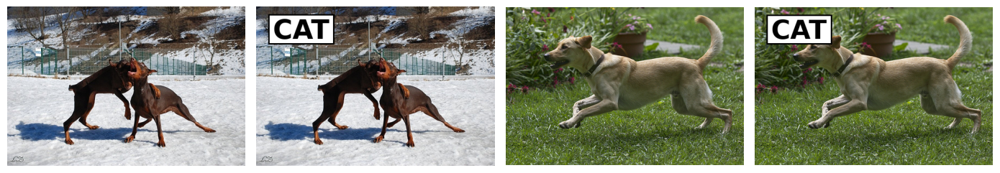

In [26]:
def add_label(img, text, frac=0.28):
    img = img.copy(); d = ImageDraw.Draw(img); W, H = img.size
    size = max(12, int(H * frac * 0.6))
    try:
        font = ImageFont.truetype("DejaVuSans-Bold.ttf", size)
    except OSError:
        font = ImageFont.load_default()
    x0, y0, x1, y1 = d.textbbox((0, 0), text, font=font)
    w, h = x1 - x0, y1 - y0; px, py = int(W * 0.05), int(H * 0.05)
    d.rectangle([px, py, px + w + 20, py + h + 20], fill="white", outline="black", width=3)
    d.text((px + 10 - x0, py + 10 - y0), text, fill="black", font=font)
    return img

PEOPLE = re.compile(r"\b(man|woman|men|women|person|people|boy|girl|child|children|kid|kids)\b", re.I)
dog_ids = [i for i, caps in enumerate(flickr_caps) if sum("dog" in c.lower() for c in caps) >= 3 and not any(PEOPLE.search(c) for c in caps)][:60]
W_dc = encode_texts(["a photo of a dog.", "a photo of a cat."])
def dog_rate(imgs): return float(((encode_images(imgs) @ W_dc.T).argmax(1) == 0).float().mean())
clean = [flickr_images[i] for i in dog_ids]
attacked = [add_label(im, "CAT") for im in clean]
control = [add_label(im, "XYZ") for im in clean]
print(f"{len(dog_ids)} изображений собак. Доля ответа 'dog': чистые {dog_rate(clean):.2f} | "
      f"табличка 'XYZ' {dog_rate(control):.2f} | табличка 'CAT' {dog_rate(attacked):.2f}")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, im in zip(axes, [clean[0], attacked[0], clean[1], attacked[1]]): ax.imshow(im); ax.axis("off")
plt.tight_layout(); plt.show()

Контроль с бессмысленной надписью «XYZ» отделяет эффект содержания надписи от эффекта самой таблички, которая закрывает часть кадра. Если доля ответов «dog» почти не меняется от «XYZ», но резко падает от «CAT», модель именно читает слово.

Следствия:

- для систем модерации и поиска это реальная уязвимость;
- для датасетов с водяными знаками, подписями на снимках, номерами и логотипами это источник паразитных признаков (лекция 4, shortcut learning).

### 9.2. Порядок слов: «мешок слов»

[Yuksekgonul et al.](https://arxiv.org/abs/2210.01936) показали, что модели вроде CLIP плохо чувствительны к порядку слов, а [Winoground](https://arxiv.org/abs/2204.03162) — что на парах подписей из одних и тех же слов модели едва превосходят случайный уровень. Простой тест: для каждого изображения сравним сходство с его подписью и с той же подписью со случайно перемешанными словами.

In [27]:
r = np.random.default_rng(0)
orig = [flickr_caps[i][0] for i in range(1000)]
def shuffle_words(s):
    w = s.rstrip(" .").split(); r.shuffle(w); return " ".join(w)
shuf = [shuffle_words(s) for s in orig]
e_o, e_s = encode_texts(orig), encode_texts(shuf)
win = ((flickr_img_emb * e_o).sum(1) > (flickr_img_emb * e_s).sum(1)).float().mean().item()
print(f"Исходная подпись ближе перемешанной в {100 * win:.1f}% случаев (случайный уровень 50%)")
print(f"Средний косинус между подписью и её перемешанной версией: {(e_o * e_s).sum(1).mean():.3f}")
for s, t in list(zip(orig, shuf))[:3]: print(f"  {s!r}\n  → {t!r}")

pairs = [("a dog chasing a man", "a man chasing a dog"), ("a white dog on a black sofa", "a black dog on a white sofa")]
for a, b in pairs:
    ea, eb = encode_texts([a, b])
    print(f"cos({a!r}, {b!r}) = {float(ea @ eb):.3f}")

Исходная подпись ближе перемешанной в 94.5% случаев (случайный уровень 50%)
Средний косинус между подписью и её перемешанной версией: 0.812
  'The dogs are in the snow in front of a fence .'
  → 'the in front are The in snow fence a of dogs'
  'a brown and white dog swimming towards some in the pool'
  → 'and pool white towards a in dog the some swimming brown'
  'A man and a woman in festive costumes dancing .'
  → 'dancing A in woman and costumes festive man a'
cos('a dog chasing a man', 'a man chasing a dog') = 0.980
cos('a white dog on a black sofa', 'a black dog on a white sofa') = 0.864


Перемешанная подпись — грамматически бессмысленный текст. В нашем прогоне модель предпочла исходную подпись в 94.5% случаев, но средний косинус между подписью и её перемешанной версией равен 0.81: порядок слов почти не меняет эмбеддинг, и в каждом двадцатом случае бессмыслица оказывается ближе к картинке. Тексты с переставленными ролями («собака гонится за человеком» и «человек гонится за собакой») получают почти одинаковые эмбеддинги: косинус 0.98.

Именно поэтому для запросов с отношениями, атрибутами и отрицаниями поверх CLIP добавляют переранжирование более сильной моделью с перекрёстным вниманием или VLM (лекция 6 курса).

### 9.3. Подсчёт объектов

Статья отмечает слабость zero-shot CLIP на подсчёте объектов (CLEVRCounts) ([Radford et al., разд. 3.1.5](https://arxiv.org/abs/2103.00020)). Сгенерируем изображения с 1–6 кругами и спросим модель «сколько». Синтетические картинки — сдвиг домена для CLIP, поэтому результат оценивает подсчёт лишь грубо.

Точность подсчёта по числу кругов: {1: 1.0, 2: 0.0, 3: 0.67, 4: 0.0, 5: 0.0, 6: 0.97} | в среднем 44% (случайно ≈ 17%)


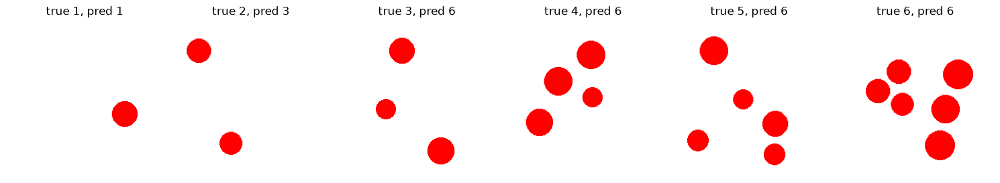

In [28]:
NUM = ["one", "two", "three", "four", "five", "six"]
def circles(n, rng, size=224):
    im = Image.new("RGB", (size, size), "white"); d = ImageDraw.Draw(im); placed = []
    while len(placed) < n:
        x, y, rad = rng.integers(30, size - 30), rng.integers(30, size - 30), rng.integers(14, 22)
        if all((x - a) ** 2 + (y - b) ** 2 > (rad + c + 6) ** 2 for a, b, c in placed):
            placed.append((x, y, rad)); d.ellipse([x - rad, y - rad, x + rad, y + rad], fill="red")
    return im
rng = np.random.default_rng(0)
cnt_imgs, cnt_y = [], []
for n in range(1, 7):
    for _ in range(30): cnt_imgs.append(circles(n, rng)); cnt_y.append(n - 1)
cnt_y = np.array(cnt_y)
W_cnt = encode_texts([f"a photo of {w} red circles." if w != "one" else "a photo of one red circle." for w in NUM])
pc = (encode_images(cnt_imgs) @ W_cnt.T).argmax(1).numpy()
print("Точность подсчёта по числу кругов:", {n + 1: round(float((pc[cnt_y == n] == n).mean()), 2) for n in range(6)},
      f"| в среднем {100 * (pc == cnt_y).mean():.0f}% (случайно ≈ 17%)")
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
for n, ax in enumerate(axes):
    i = np.where(cnt_y == n)[0][0]; ax.imshow(cnt_imgs[i]); ax.axis("off"); ax.set_title(f"true {n + 1}, pred {pc[i] + 1}", fontsize=12)
plt.tight_layout(); plt.show()

В нашем прогоне один круг распознаётся всегда, а начиная с трёх кругов модель почти всегда отвечает «six». Средняя точность 44% выше случайных 17% в основном за счёт классов 1 и 6. Модель не считает, а различает «один объект» и «много объектов» и выбирает наиболее «многочисленное» слово. Такой перекос к одному ответу — типичное поведение zero-shot-классификатора вне его домена. Это согласуется со слабым результатом CLIP на CLEVRCounts в статье.

## 10. Мини-обучение: дообучаем проекции на Flickr8k

Чтобы связать теорию с кодом, дообучим только две линейные проекции CLIP. Энкодеры заморожены, поэтому это быстро даже на CPU. Используется функция потерь из раздела 3: 800 изображений идут на обучение, 200 — на проверку.

Цель не улучшить CLIP: на 800 изображениях это невозможно без переобучения. Цель — увидеть, как ведут себя потеря, температура и метрики при контрастном обучении.

совпадение с get_image_features: True


обучение заняло 2 с
R@1 на валидации до дообучения (T→I, I→T): (np.float64(75.0), np.float64(89.5))


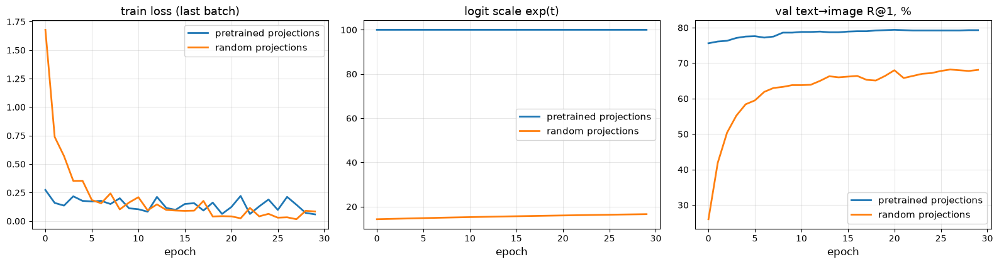

In [29]:
@torch.no_grad()
def pre_projection(images=None, texts=None, bs=64):
    """Признаки до проекции: pooler_output энкодера (перед visual/text_projection)."""
    out = []
    if images is not None:
        for i in range(0, len(images), bs):
            x = processor.image_processor(images=images[i:i + bs], return_tensors="pt")["pixel_values"].to(DEVICE)
            out.append(model.vision_model(pixel_values=x).pooler_output.float().cpu())
    else:
        for i in range(0, len(texts), 256):
            t = tokenizer(texts[i:i + 256], padding=True, truncation=True, return_tensors="pt").to(DEVICE)
            out.append(model.text_model(**t).pooler_output.float().cpu())
    return torch.cat(out)

hv = pre_projection(images=flickr_images)            # [1000, 768]
ht = pre_projection(texts=all_caps)                  # [5000, 512]
# Проверка: проекция pooler_output даёт те же эмбеддинги, что get_*_features
Wv0, Wt0 = model.visual_projection.weight.detach().cpu().float(), model.text_projection.weight.detach().cpu().float()
print("совпадение с get_image_features:", torch.allclose(F.normalize(hv @ Wv0.T, dim=-1), flickr_img_emb, atol=1e-4))

tr_ids, va_ids = np.arange(800), np.arange(800, 1000)
def val_r1(Wv, Wt, log_s=None):
    I_ = F.normalize(hv[va_ids] @ Wv.T, dim=-1)
    tsel = np.concatenate([np.arange(5 * i, 5 * i + 5) for i in va_ids])
    T_ = F.normalize(ht[tsel] @ Wt.T, dim=-1)
    m, _ = retrieval_metrics(I_, T_, np.repeat(np.arange(len(va_ids)), 5), ks=(1,))
    return m["T→I R@1"], m["I→T R@1"]

def train_projections(init="pretrained", epochs=30, bs=128, lr=1e-4, seed=0):
    g = torch.Generator().manual_seed(seed)
    if init == "pretrained":
        Wv, Wt, log_s = Wv0.clone(), Wt0.clone(), torch.tensor(math.log(100.0))
    else:  # случайные проекции, температура как в начале обучения CLIP (τ = 0.07)
        Wv, Wt = torch.randn(512, 768, generator=g) / math.sqrt(768), torch.randn(512, 512, generator=g) / math.sqrt(512)
        log_s = torch.tensor(math.log(1 / 0.07))
    Wv, Wt, log_s = Wv.requires_grad_(), Wt.requires_grad_(), log_s.requires_grad_()
    opt = torch.optim.AdamW([Wv, Wt, log_s], lr=lr, weight_decay=0.01)
    hist = []
    for ep in range(epochs):
        perm = tr_ids[torch.randperm(len(tr_ids), generator=g).numpy()]
        for b in range(0, len(perm), bs):
            ids = perm[b:b + bs]
            cap = torch.randint(0, 5, (len(ids),), generator=g).numpy()       # случайная из 5 подписей
            I_ = F.normalize(hv[ids] @ Wv.T, dim=-1); T_ = F.normalize(ht[5 * ids + cap] @ Wt.T, dim=-1)
            loss, _ = clip_loss(I_, T_, log_s.exp())
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): log_s.clamp_(0, math.log(100))                # ограничение масштаба, как в CLIP
        with torch.no_grad(): hist.append((loss.item(), log_s.exp().item(), *val_r1(Wv, Wt)))
    return np.array(hist)

t0 = time.time()
h_pre = train_projections("pretrained", lr=1e-5)
h_rand = train_projections("random", lr=1e-3)
print(f"обучение заняло {time.time() - t0:.0f} с")
print("R@1 на валидации до дообучения (T→I, I→T):", tuple(round(v, 1) for v in val_r1(Wv0, Wt0)))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for h, lab in [(h_pre, "pretrained projections"), (h_rand, "random projections")]:
    axes[0].plot(h[:, 0], lw=2, label=lab); axes[1].plot(h[:, 1], lw=2, label=lab); axes[2].plot(h[:, 2], lw=2, label=lab)
for ax, t in zip(axes, ["train loss (last batch)", "logit scale exp(t)", "val text→image R@1, %"]):
    ax.set_title(t, fontsize=13); ax.set_xlabel("epoch", fontsize=12); ax.grid(alpha=.3); ax.legend(fontsize=11)
plt.tight_layout(); plt.show()

Что видно на графиках:

- Случайные проекции поверх замороженных энкодеров всего за 30 эпох на 800 изображениях поднимают text → image R@1 на валидации примерно с 26% до 68%. Предобученные проекции дают 75% ещё до дообучения. Большая часть «знания» содержится в энкодерах, а проекции согласуют два пространства. Эта идея лежит в основе [LiT](https://arxiv.org/abs/2111.07991), где замораживается сильный энкодер изображений и обучается только текстовая часть. Чтобы догнать проекции, обученные на 400 млн пар, 800 изображений не хватает.
- Обучаемый масштаб логитов у случайных проекций растёт, но медленно: примерно от $1/0.07\approx14$ до 17 за 30 эпох. Градиент по $t$ положителен, пока модель в основном права (теоретическая часть, раздел 3). В полном обучении CLIP за сотни тысяч шагов масштаб дошёл до ограничения 100. У предобученных проекций он остаётся на ограничении.
- Дообучение предобученных проекций на Flickr8k подняло валидационный R@1 примерно с 75% до 79%: стиль подписей Flickr8k отличается от веб-текстов, и проекции под него подстраиваются. Валидация здесь из того же домена. На других данных такая подстройка может ухудшить качество, и от этого защищают методы вроде [WiSE-FT](https://arxiv.org/abs/2109.01903), которые усредняют веса исходной и дообученной моделей.

In [30]:
RUN_SIGLIP = True   # поставьте False, чтобы пропустить (на CPU раздел занимает несколько минут)

## 11. Сравнение с SigLIP

[SigLIP](https://arxiv.org/abs/2303.15343) заменяет softmax по батчу независимыми бинарными задачами «пара или не пара» с сигмоидой. Повторим две основные задачи блокнота с моделью [google/siglip-base-patch16-224](https://huggingface.co/google/siglip-base-patch16-224).

Важная деталь: в [карточке модели](https://huggingface.co/google/siglip-base-patch16-224) тексты токенизируются с `padding="max_length"` — дополнением до фиксированной длины (у этой модели 64 токена). При обычном `padding=True` сходства получаются другими.

In [31]:
if RUN_SIGLIP:
    from transformers import AutoModel, AutoProcessor
    SIG_ID = "google/siglip-base-patch16-224"
    sig_model = AutoModel.from_pretrained(SIG_ID).to(DEVICE).eval()
    sig_proc = AutoProcessor.from_pretrained(SIG_ID)
    sig_tok = sig_proc.tokenizer
    sig_text = lambda texts: encode_texts(texts, m=sig_model, tok=sig_tok, padding="max_length", max_length=64)
    t0 = time.time()
    s_cifar = encode_images(cifar_te_img, m=sig_model, proc=sig_proc)
    s_flk = encode_images(flickr_images, m=sig_model, proc=sig_proc)
    W_sig = zeroshot_classifier(CIFAR_CLASSES, CIFAR_TEMPLATES, encode=sig_text)
    acc_sig = float(((s_cifar @ W_sig.T).argmax(1).numpy() == cifar_te_y).mean())
    s_txt = sig_text(["a photo of " + lower_first(c) for c in all_caps])
    m_sig, _ = retrieval_metrics(s_flk, s_txt, cap2img)
    print(f"SigLIP посчитан за {time.time() - t0:.0f} с")
    print(f"{'':22s}{'CIFAR-10 zero-shot':>20s}{'T→I R@1':>10s}{'I→T R@1':>10s}")
    print(f"{'CLIP ViT-B/32':22s}{100 * zs_acc:20.1f}{m_pref['T→I R@1']:10.1f}{m_pref['I→T R@1']:10.1f}")
    print(f"{'SigLIP ViT-B/16':22s}{100 * acc_sig:20.1f}{m_sig['T→I R@1']:10.1f}{m_sig['I→T R@1']:10.1f}")

    # Вероятности SigLIP — независимые сигмоиды, их сумма не обязана быть 1
    ts, tb = sig_model.logit_scale.exp().item(), sig_model.logit_bias.item()
    lab = ["two dogs playing in the snow", "a dog", "a cat sleeping on a sofa", "a photo of a pizza"]
    z = ts * (s_flk[0:1] @ sig_text(lab).T)[0] + tb
    print(f"\nlogit_scale = {ts:.1f}, logit_bias = {tb:.1f}")
    for l, p in zip(lab, torch.sigmoid(z).numpy()): print(f"  P(match | {l!r}) = {p:.3f}")
    print("  сумма =", round(float(torch.sigmoid(z).sum()), 3))

SigLIP посчитан за 606 с
                        CIFAR-10 zero-shot   T→I R@1   I→T R@1
CLIP ViT-B/32                         90.0      55.0      72.2
SigLIP ViT-B/16                       92.8      72.4      86.2

logit_scale = 117.3, logit_bias = -12.9
  P(match | 'two dogs playing in the snow') = 0.233
  P(match | 'a dog') = 0.001
  P(match | 'a cat sleeping on a sofa') = 0.000
  P(match | 'a photo of a pizza') = 0.000
  сумма = 0.234


SigLIP отвечает на вопрос «подходит ли этот текст к картинке» независимо для каждого текста. Поэтому сразу несколько описаний могут получить высокую вероятность, и ни одно может не получить. Для поиска и мультиметочной разметки это удобнее, чем softmax CLIP. Сравнение двух моделей здесь неравное: у SigLIP другой размер патча (16 против 32), другие данные и другой рецепт обучения. Это сравнение готовых чекпойнтов, а не двух функций потерь при прочих равных.

## 12. Итоги практики

| Наблюдение | Раздел |
|---|---|
| Масштаб логитов обучен до ограничения 100; без него softmax почти равномерен | 0, 3 |
| Промпт и ансамбль шаблонов — часть классификатора; разница между ними требует статистической проверки | 4 |
| Вероятности zero-shot нужно калибровать на своём домене | 4 |
| При 1–2 примерах на класс текстовый классификатор лучше линейного; при большей разметке — наоборот; их можно сочетать | 5 |
| Поиск работает «из коробки»; ошибки часто — неполнота эталона | 6 |
| Отрицания и порядок слов кодируются плохо | 6, 9.2 |
| Модальности разнесены; абсолютные пороги косинуса непереносимы | 8 |
| CLIP читает текст на изображении — типографская атака | 9.1 |
| Основное знание — в энкодерах: случайные проекции за 30 эпох дают R@1 около 68%; подстройка проекций под домен добавляет несколько пунктов | 10 |

# Контрольные вопросы

1. Почему контрастная цель обучает zero-shot-распознаванию эффективнее, чем генерация подписи? Какие два множителя эффективности приводят авторы?
2. Сколько позитивных и негативных пар в батче CLIP размера $N$? Сколько негативов у одного изображения при $N=32\,768$?
3. Запишите симметричную функцию потерь CLIP. Чем $\mathcal L_{I\to T}$ отличается от $\mathcal L_{T\to I}$?
4. Выведите $\partial\mathcal L/\partial z_{ij}$. Какие негативы отталкиваются сильнее?
5. Почему обучаемый масштаб логитов растёт во время обучения и зачем его ограничивают значением 100?
6. Объясните, почему zero-shot-классификатор CLIP — это логистическая регрессия, веса которой написал текстовый энкодер.
7. Почему ансамбль промптов усредняют в пространстве эмбеддингов, а не вероятностей?
8. Приведите два примера многозначности имён классов и способ её устранения промптом.
9. На каких типах задач zero-shot CLIP заметно уступает linear probe на ResNet-50 и почему?
10. Почему zero-shot CLIP соответствует 4-shot, а не 0.5-shot логистической регрессии?
11. Что такое effective robustness? Что происходит с ней после адаптации CLIP к ImageNet?
12. Чем dual encoder отличается от cross-encoder в поиске? Как их сочетают?
13. Почему I→T R@1 на Flickr30k выше, чем T→I R@1?
14. Сколько памяти займёт индекс из 10 млн изображений с $d=768$ в float16?
15. Что такое модальный разрыв и каковы его причины по Liang et al.? Почему из-за него абсолютные пороги косинуса непереносимы?
16. Почему CLIP плохо различает «собака кусает человека» и «человек кусает собаку»? Какой приём обучения помогает?
17. Что такое типографская атака? Как отделить эффект надписи от эффекта перекрытия части кадра?
18. Как выбор набора классов влияет на смещения zero-shot-классификатора людей? Приведите пример из статьи CLIP.
19. Сравните CoOp, Tip-Adapter, LiT и WiSE-FT: что обучается в каждом?
20. Чем функция потерь SigLIP отличается от CLIP? Зачем смещение $b=-10$ при инициализации?
21. Что показали DataComp и MetaCLIP о роли данных?

# Задания

1. **Промпты для своего домена.**
   - Выберите 5–10 классов из своего проекта.
   - Сравните на валидации: голые имена; «a photo of a {}»; доменный шаблон; ансамбль; описания, сгенерированные LLM (CuPL).
   - Проверьте значимость разницы тестом Мак-Немара.
2. **Кривая по разметке.** Повторите раздел 5 практики на своих данных при 1, 2, 4, 8, 16 примерах на класс и 10 seed. Подберите $\alpha$ и $\beta$ Tip-Adapter на валидации и сравните с фиксированными $\alpha=1,\ \beta=5$.
3. **Поиск.**
   - Постройте индекс из 1000+ изображений своего домена.
   - Сформулируйте 30 запросов и разметите вручную релевантность top-10.
   - Посчитайте Precision@10 и сравните с Recall@K по формальному эталону.
4. **Отрицания и отношения.**
   - Составьте 20 пар запросов вида «X с Y» / «X без Y» и 20 пар с переставленными ролями.
   - Измерьте, как часто CLIP ранжирует их правильно.
   - Повторите с SigLIP.
5. **Типографский аудит.**
   - Нанесите на 100 изображений своего домена надписи с названиями чужих классов и бессмысленные надписи того же размера.
   - Постройте зависимость доли ошибок от размера надписи.
6. **Калибровка.** Постройте диаграмму надёжности (reliability diagram) до и после temperature scaling. Как меняется ECE при подборе масштаба на другом домене?
7. **Модель побольше.** Замените `MODEL_ID` на `openai/clip-vit-base-patch16` или `openai/clip-vit-large-patch14` (на GPU). Перезапустите разделы 4 и 6. Как изменились zero-shot-точность и R@1? Сопоставьте это с затратами времени.
8. **Мини-LiT.** В разделе 10 замените случайные проекции на MLP с одним скрытым слоем. Сравните с линейными проекциями по R@1 на валидации. Согласуется ли результат с выводом авторов CLIP о линейной проекции?

# Источники

Основная статья:

- Radford A. et al. Learning Transferable Visual Models From Natural Language Supervision (CLIP), 2021 — https://arxiv.org/abs/2103.00020
- Репозиторий CLIP и шаблоны промптов — https://github.com/openai/CLIP, https://github.com/openai/CLIP/blob/main/data/prompts.md

Данные и масштабирование:

- Jia C. et al. Scaling Up Visual and Vision-Language Representation Learning With Noisy Text Supervision (ALIGN), 2021 — https://arxiv.org/abs/2102.05918
- Schuhmann C. et al. LAION-5B, 2022 — https://arxiv.org/abs/2210.08402
- Cherti M. et al. Reproducible scaling laws for contrastive language-image learning (OpenCLIP), 2022 — https://arxiv.org/abs/2212.07143; репозиторий — https://github.com/mlfoundations/open_clip
- Gadre S. Y. et al. DataComp, 2023 — https://arxiv.org/abs/2304.14108
- Xu H. et al. Demystifying CLIP Data (MetaCLIP), 2023 — https://arxiv.org/abs/2309.16671

Функции потерь и модели:

- van den Oord A. et al. Representation Learning with Contrastive Predictive Coding, 2018 — https://arxiv.org/abs/1807.03748
- Zhai X. et al. Sigmoid Loss for Language Image Pre-Training (SigLIP), 2023 — https://arxiv.org/abs/2303.15343
- Tschannen M. et al. SigLIP 2, 2025 — https://arxiv.org/abs/2502.14786
- Zhai X. et al. LiT: Zero-Shot Transfer with Locked-image text Tuning, 2021 — https://arxiv.org/abs/2111.07991

Адаптация:

- Zhou K. et al. Learning to Prompt for Vision-Language Models (CoOp), 2021 — https://arxiv.org/abs/2109.01134
- Pratt S. et al. What does a platypus look like? (CuPL), 2022 — https://arxiv.org/abs/2209.03320
- Zhang R. et al. Tip-Adapter, 2021 — https://arxiv.org/abs/2111.03930
- Wortsman M. et al. Robust fine-tuning of zero-shot models (WiSE-FT), 2021 — https://arxiv.org/abs/2109.01903

Геометрия и ограничения:

- Liang W. et al. Mind the Gap: Understanding the Modality Gap in Multi-modal Contrastive Representation Learning, 2022 — https://arxiv.org/abs/2203.02053
- Yuksekgonul M. et al. When and why vision-language models behave like bags-of-words (ARO), 2022 — https://arxiv.org/abs/2210.01936
- Thrush T. et al. Winoground, 2022 — https://arxiv.org/abs/2204.03162
- Goh G. et al. Multimodal Neurons in Artificial Neural Networks. Distill, 2021 — https://distill.pub/2021/multimodal-neurons/
- Пересказ примеров типографской атаки — https://mjtsai.com/blog/2021/03/04/multimodal-neurons-in-artificial-neural-networks/

Применения CLIP-пространства:

- Hessel J. et al. CLIPScore, 2021 — https://arxiv.org/abs/2104.08718
- Minderer M. et al. Simple Open-Vocabulary Object Detection with Vision Transformers (OWL-ViT), 2022 — https://arxiv.org/abs/2205.06230
- Lüddecke T., Ecker A. Image Segmentation Using Text and Image Prompts (CLIPSeg), 2021 — https://arxiv.org/abs/2112.10003
- Ramesh A. et al. Hierarchical Text-Conditional Image Generation with CLIP Latents (unCLIP), 2022 — https://arxiv.org/abs/2204.06125
- FAISS — https://github.com/facebookresearch/faiss

Данные и модели блокнота:

- Flickr8k (тестовая часть, зеркало на HF) — https://huggingface.co/datasets/jxie/flickr8k
- CIFAR-10 (зеркало на HF) — https://huggingface.co/datasets/uoft-cs/cifar10
- openai/clip-vit-base-patch32 — https://huggingface.co/openai/clip-vit-base-patch32
- google/siglip-base-patch16-224 — https://huggingface.co/google/siglip-base-patch16-224
- Изображения с яблоком (OpenAI) — https://cdn.openai.com/multimodal-neurons/assets/apple/apple-blank.jpg, https://cdn.openai.com/multimodal-neurons/assets/apple/apple-ipod.jpg
- Пример zero-shot с яблоком в AutoGluon — https://auto.gluon.ai/stable/tutorials/multimodal/image_prediction/clip_zeroshot.html